# 03 - Exploratory Data Analysis (EDA)

## Project
India Air Quality Intelligence — From Raw Data to Pollution Risk Insights

## Objective
Explore historical hourly AQI patterns across Indian cities,
states, stations, and time periods.

## Key Questions

1. What does the overall AQI distribution look like?
2. Which cities and states have the highest average AQI?
3. How does air quality vary across months and seasons?
4. What are the hourly pollution patterns?
5. How has AQI changed between 2017 and 2023?
6. Which monitoring stations consistently report poor air quality?
7. Are there meaningful differences in pollution patterns
   across geographical regions?

## Dataset
Source: CPCB-derived India air quality dataset.

Processed file: air_quality_analytical.parquet

## Analytical Approach
- Descriptive statistics
- Data visualization
- Time-series exploration
- Geographic comparisons
- Station-level analysis

## Important Considerations
- Missing observations will not be treated as zero.
- Out-of-range AQI readings are excluded from standard AQI analysis.
- Changing monitoring station coverage will be considered
  when comparing annual trends.

In [4]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# ==========================================
# 2. LOAD ANALYTICAL DATASET
# ==========================================

PROJECT_ROOT = Path.cwd().parent

ANALYTICAL_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "air_quality_analytical.parquet"
)

df = pd.read_parquet(ANALYTICAL_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (13509072, 11)


,Station ID,State,City,Station Name,Date,Hour,AQI,Timestamp,Station,AQI_Status,AQI_Valid
0,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-11,00:00:00,NaN,2017-12-11,Andhra Pradesh | Amaravati | Secretariat Amara...,missing,NaN
1,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-12,00:00:00,263.0,2017-12-12,Andhra Pradesh | Amaravati | Secretariat Amara...,valid,263.0
2,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-13,00:00:00,137.0,2017-12-13,Andhra Pradesh | Amaravati | Secretariat Amara...,valid,137.0
3,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-14,00:00:00,85.0,2017-12-14,Andhra Pradesh | Amaravati | Secretariat Amara...,valid,85.0
4,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-15,00:00:00,127.0,2017-12-15,Andhra Pradesh | Amaravati | Secretariat Amara...,valid,127.0


In [6]:
# ==========================================
# 3. FEATURE EXTRACTION
# ==========================================

df["Year"] = df["Timestamp"].dt.year
df["Month"] = df["Timestamp"].dt.month
df["Day"] = df["Timestamp"].dt.day
df["Hour_Number"] = df["Timestamp"].dt.hour
df["Day_Name"] = df["Timestamp"].dt.day_name()
df["Month_Name"] = df["Timestamp"].dt.month_name()

# Define Indian meteorological-style seasons
def assign_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Summer"

    elif month in [6, 7, 8, 9]:
        return "Monsoon"

    else:
        return "Post-Monsoon"


df["Season"] = df["Month"].apply(assign_season)

display(
    df[
        [
            "Timestamp",
            "Year",
            "Month",
            "Hour_Number",
            "Day_Name",
            "Month_Name",
            "Season",
            "AQI_Valid"
        ]
    ].head(10)
)

,Timestamp,Year,Month,Hour_Number,Day_Name,Month_Name,Season,AQI_Valid
0,2017-12-11,2017,12,0,Monday,December,Winter,NaN
1,2017-12-12,2017,12,0,Tuesday,December,Winter,263.0
2,2017-12-13,2017,12,0,Wednesday,December,Winter,137.0
3,2017-12-14,2017,12,0,Thursday,December,Winter,85.0
4,2017-12-15,2017,12,0,Friday,December,Winter,127.0
5,2017-12-16,2017,12,0,Saturday,December,Winter,153.0
6,2017-12-17,2017,12,0,Sunday,December,Winter,280.0
7,2017-12-18,2017,12,0,Monday,December,Winter,314.0
8,2017-12-19,2017,12,0,Tuesday,December,Winter,256.0
9,2017-12-20,2017,12,0,Wednesday,December,Winter,294.0


In [7]:
# ==========================================
# 4. DATASET VALIDATION
# ==========================================

print("Dataset shape:", df.shape)

print("\nDate range:")
print("Start:", df["Timestamp"].min())
print("End:", df["Timestamp"].max())

print("\nUnique values:")
print("Years:", sorted(df["Year"].unique()))
print("Months:", df["Month"].nunique())
print("States:", df["State"].nunique())
print("Cities:", df["City"].nunique())
print("Stations:", df["Station"].nunique())

print("\nSeason distribution:")
display(df["Season"].value_counts())

print("\nAQI availability:")
print("Valid AQI:", df["AQI_Valid"].notna().sum())
print("Missing AQI:", df["AQI_Valid"].isna().sum())

print("\nData types:")
display(df.dtypes)

Dataset shape: (13509072, 18)

Date range:
Start: 2017-01-01 00:00:00
End: 2023-12-31 23:00:00

Unique values:
Years: [np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]
Months: 12
States: 29
Cities: 248
Stations: 529

Season distribution:


Season
Monsoon         4556496
Winter          3302880
Summer          3195408
Post-Monsoon    2454288
Name: count, dtype: int64


AQI availability:
Valid AQI: 12473485
Missing AQI: 1035587

Data types:


Station ID                 str
State                      str
City                       str
Station Name               str
Date            datetime64[us]
Hour                       str
AQI                    float64
Timestamp       datetime64[us]
Station                    str
AQI_Status                 str
AQI_Valid              float64
Year                     int32
Month                    int32
Day                      int32
Hour_Number              int32
Day_Name                   str
Month_Name                 str
Season                     str
dtype: object

In [8]:
# ==========================================
# 5A. AQI CATEGORY CLASSIFICATION
# ==========================================

aqi_bins = [0, 50, 100, 200, 300, 400, 500]

aqi_labels = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

df["AQI_Category"] = pd.cut(
    df["AQI_Valid"],
    bins=aqi_bins,
    labels=aqi_labels,
    include_lowest=True
)

print("AQI categories created!")

display(
    df[["AQI_Valid", "AQI_Category"]].sample(10, random_state=42)
)

AQI categories created!


,AQI_Valid,AQI_Category
10712772,NaN,NaN
8218077,NaN,NaN
5551882,242.0,Poor
9467167,113.0,Moderate
12375992,319.0,Very Poor
8151637,118.0,Moderate
8355486,58.0,Satisfactory
7659233,39.0,Good
7973515,114.0,Moderate
10741006,173.0,Moderate


In [9]:
# ==========================================
# 5B. AQI CATEGORY DISTRIBUTION
# ==========================================

category_summary = (
    df["AQI_Category"]
    .value_counts()
    .reindex(aqi_labels)
    .to_frame(name="Observations")
)

category_summary["Percentage"] = (
    category_summary["Observations"]
    / category_summary["Observations"].sum()
    * 100
)

category_summary["Percentage"] = (
    category_summary["Percentage"].round(2)
)

display(category_summary)

,Observations,Percentage
AQI_Category,,
Good,2278540,18.27
Satisfactory,3958356,31.73
Moderate,3656970,29.32
Poor,1023263,8.20
Very Poor,1106391,8.87
Severe,449965,3.61


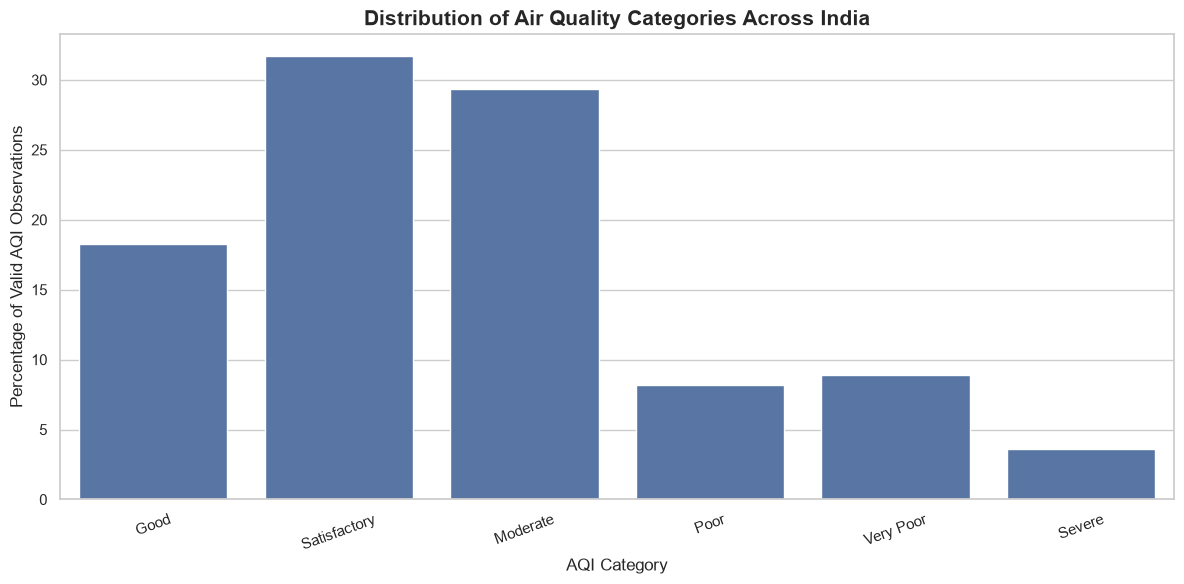

In [10]:
# ==========================================
# 5C. AQI CATEGORY BAR CHART
# ==========================================

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_summary.index,
    y=category_summary["Percentage"]
)

plt.title(
    "Distribution of Air Quality Categories Across India",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("AQI Category")
plt.ylabel("Percentage of Valid AQI Observations")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

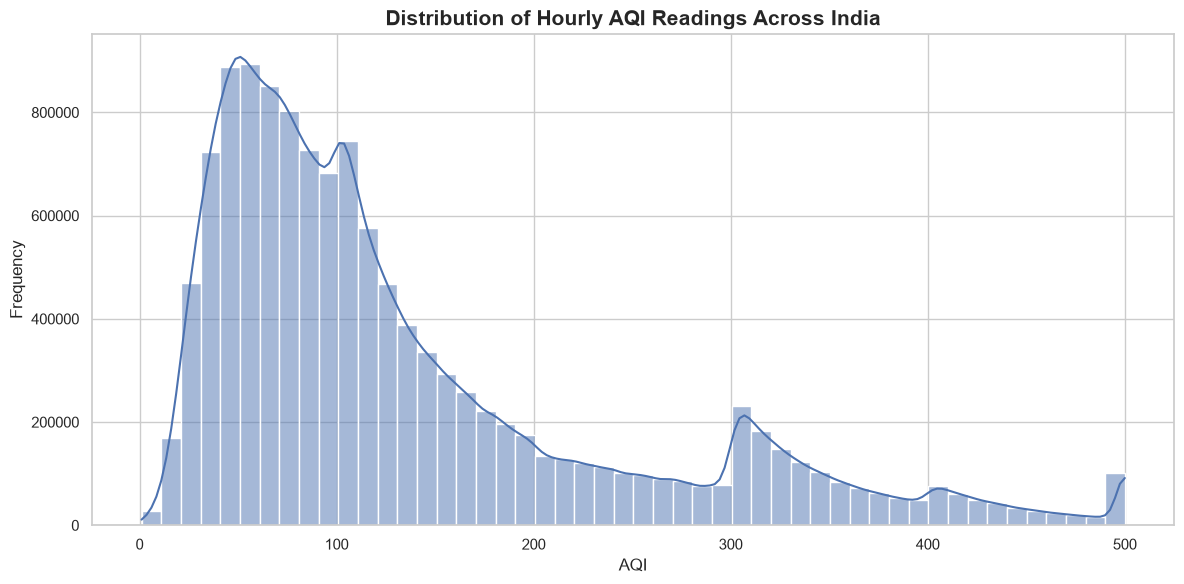

In [11]:
# ==========================================
# 5D. AQI HISTOGRAM
# ==========================================

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="AQI_Valid",
    bins=50,
    kde=True
)

plt.title(
    "Distribution of Hourly AQI Readings Across India",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [12]:
print("Original AQI missing:", df["AQI"].isna().sum())

print(
    "Out-of-range AQI:",
    df["AQI_Status"].eq("out_of_range").sum()
)

print("Valid AQI:", df["AQI_Valid"].notna().sum())

print(
    "Excluded from analytical AQI:",
    df["AQI_Valid"].isna().sum()
)

Original AQI missing: 1035531
Out-of-range AQI: 56
Valid AQI: 12473485
Excluded from analytical AQI: 1035587


## EDA Finding 1: Overall AQI Distribution

### Key Observations

1. Satisfactory AQI readings represent 31.73% of valid observations.
2. Moderate readings account for 29.32%.
3. Good AQI readings account for 18.27%.
4. Poor, Very Poor, and Severe categories together represent 20.68%.
5. The AQI distribution is positively skewed, with a concentration
   at lower-to-moderate values and a long upper tail.

### Business Interpretation

The dataset indicates that elevated pollution readings are a
substantial part of the observed monitoring data.

Approximately one-fifth of valid hourly observations fall into
the Poor, Very Poor, or Severe categories.

This highlights the importance of identifying geographical
hotspots and understanding seasonal pollution patterns.

### Analytical Limitation

These percentages represent hourly monitoring observations,
not population exposure or the percentage of Indian citizens
experiencing each AQI category.

Stations with more observations can contribute more heavily
to the overall distribution.

In [13]:
# ==========================================
# 6A. CITY-WISE AQI ANALYSIS
# ==========================================

city_summary = (
    df.dropna(subset=["AQI_Valid"])
    .groupby(["State", "City"])
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Minimum_AQI=("AQI_Valid", "min"),
        Maximum_AQI=("AQI_Valid", "max"),
        Valid_Observations=("AQI_Valid", "count"),
        Number_of_Stations=("Station", "nunique")
    )
    .reset_index()
)

city_summary = city_summary.round({
    "Average_AQI": 2,
    "Median_AQI": 2
})

print("Number of cities:", len(city_summary))

display(
    city_summary.sort_values(
        "Average_AQI",
        ascending=False
    ).head(20)
)

Number of cities: 248


,State,City,Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Valid_Observations,Number_of_Stations
153,Odisha,Angul,241.32,247.0,28.0,500.0,1546,1
9,Assam,Byrnihat,233.83,177.0,2.0,500.0,7825,1
78,Jharkhand,Pathardih,231.13,192.0,110.0,437.0,527,1
227,Uttar Pradesh,Ghaziabad,222.28,186.0,1.0,500.0,132892,3
182,Rajasthan,Bhiwadi,220.82,195.0,1.0,500.0,48913,1
243,West Bengal,Barrackpore,219.01,231.0,20.0,392.0,677,1
44,Delhi,Delhi,214.90,178.0,1.0,500.0,1777818,39
236,Uttar Pradesh,Noida,210.92,173.0,1.0,500.0,254860,6
23,Bihar,Katihar,208.74,160.0,1.0,500.0,17036,1
157,Odisha,Bhubaneswar,206.74,197.0,26.0,500.0,3078,2


In [14]:
# ==========================================
# 6B. CITY-WISE POOR AQI FREQUENCY
# ==========================================

valid_df = df.dropna(subset=["AQI_Valid"]).copy()

valid_df["Poor_AQI_Flag"] = (
    valid_df["AQI_Category"].isin(
        ["Poor", "Very Poor", "Severe"]
    )
)

poor_city_summary = (
    valid_df.groupby(["State", "City"])
    .agg(
        Total_Observations=("AQI_Valid", "count"),
        Poor_Observations=("Poor_AQI_Flag", "sum")
    )
    .reset_index()
)

poor_city_summary["Poor_AQI_Percentage"] = (
    poor_city_summary["Poor_Observations"]
    / poor_city_summary["Total_Observations"]
    * 100
).round(2)

display(
    poor_city_summary.sort_values(
        "Poor_AQI_Percentage",
        ascending=False
    ).head(20)
)

,State,City,Total_Observations,Poor_Observations,Poor_AQI_Percentage
153,Odisha,Angul,1546,926,59.90
243,West Bengal,Barrackpore,677,398,58.79
161,Odisha,Cuttack,1466,772,52.66
157,Odisha,Bhubaneswar,3078,1509,49.03
182,Rajasthan,Bhiwadi,48913,23778,48.61
9,Assam,Byrnihat,7825,3672,46.93
227,Uttar Pradesh,Ghaziabad,132892,61542,46.31
44,Delhi,Delhi,1777818,801148,45.06
31,Bihar,Saharsa,15764,6955,44.12
236,Uttar Pradesh,Noida,254860,110096,43.20


In [15]:
# ==========================================
# 6C. CITY RANKING WITH COVERAGE FILTER
# ==========================================

MIN_OBSERVATIONS = 10000

# Filter cities based on minimum observations
reliable_cities = city_summary[
    city_summary["Valid_Observations"] >= MIN_OBSERVATIONS
].copy()

# Rank by average AQI
reliable_cities = reliable_cities.sort_values(
    "Average_AQI",
    ascending=False
)

print("Total cities:", len(city_summary))

print(
    "Cities with at least",
    MIN_OBSERVATIONS,
    "observations:",
    len(reliable_cities)
)

display(
    reliable_cities[
        [
            "State",
            "City",
            "Average_AQI",
            "Median_AQI",
            "Valid_Observations",
            "Number_of_Stations"
        ]
    ].head(20)
)

Total cities: 248
Cities with at least 10000 observations: 168


,State,City,Average_AQI,Median_AQI,Valid_Observations,Number_of_Stations
227,Uttar Pradesh,Ghaziabad,222.28,186.0,132892,3
182,Rajasthan,Bhiwadi,220.82,195.0,48913,1
44,Delhi,Delhi,214.90,178.0,1777818,39
236,Uttar Pradesh,Noida,210.92,173.0,254860,6
23,Bihar,Katihar,208.74,160.0,17036,1
31,Bihar,Saharsa,204.75,173.0,15764,1
57,Haryana,Faridabad,202.00,167.0,131396,4
223,Uttar Pradesh,Baghpat,201.67,167.0,39614,2
20,Bihar,Darbhanga,200.38,157.0,10183,1
34,Bihar,Siwan,200.18,155.0,16465,1


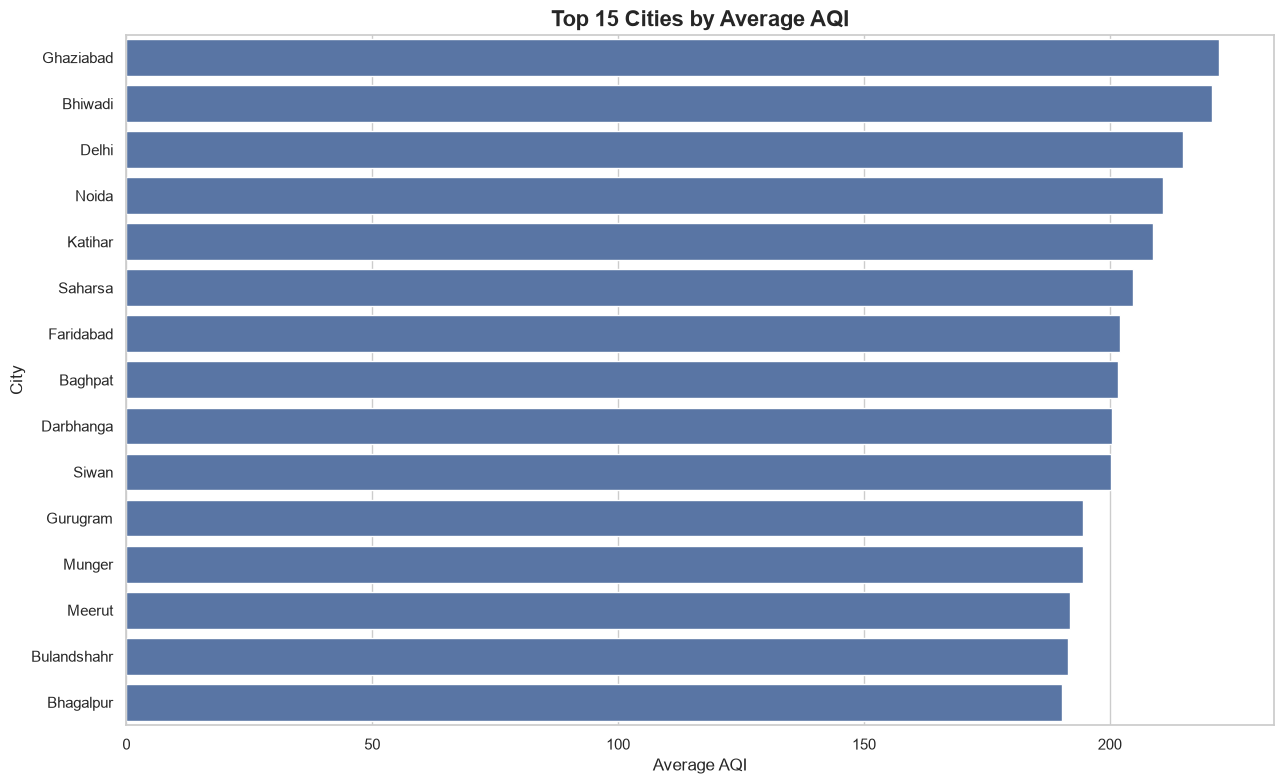

In [16]:
# ==========================================
# 6D. TOP 15 CITIES BY AVERAGE AQI
# ==========================================

top_15_cities = reliable_cities.head(15).copy()

plt.figure(figsize=(13, 8))

sns.barplot(
    data=top_15_cities,
    x="Average_AQI",
    y="City"
)

plt.title(
    "Top 15 Cities by Average AQI",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Average AQI")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# 6E. POOR AQI FREQUENCY WITH COVERAGE FILTER
# ==========================================

reliable_poor_cities = poor_city_summary[
    poor_city_summary["Total_Observations"] >= MIN_OBSERVATIONS
].copy()

reliable_poor_cities = reliable_poor_cities.sort_values(
    "Poor_AQI_Percentage",
    ascending=False
)

display(reliable_poor_cities.head(20))

,State,City,Total_Observations,Poor_Observations,Poor_AQI_Percentage
182,Rajasthan,Bhiwadi,48913,23778,48.61
227,Uttar Pradesh,Ghaziabad,132892,61542,46.31
44,Delhi,Delhi,1777818,801148,45.06
31,Bihar,Saharsa,15764,6955,44.12
236,Uttar Pradesh,Noida,254860,110096,43.20
223,Uttar Pradesh,Baghpat,39614,16820,42.46
23,Bihar,Katihar,17036,7151,41.98
57,Haryana,Faridabad,131396,54989,41.85
20,Bihar,Darbhanga,10183,4239,41.63
59,Haryana,Gurugram,144826,59982,41.42


In [18]:
# ==========================================
# 7A. STATE-WISE AQI ANALYSIS
# ==========================================

state_summary = (
    valid_df.groupby("State")
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Minimum_AQI=("AQI_Valid", "min"),
        Maximum_AQI=("AQI_Valid", "max"),
        Valid_Observations=("AQI_Valid", "count"),
        Number_of_Cities=("City", "nunique"),
        Number_of_Stations=("Station", "nunique")
    )
    .reset_index()
)

state_summary = state_summary.round({
    "Average_AQI": 2,
    "Median_AQI": 2
})

state_summary = state_summary.sort_values(
    "Average_AQI",
    ascending=False
)

display(state_summary)

,State,Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Valid_Observations,Number_of_Cities,Number_of_Stations
6,Delhi,214.90,178.0,1.0,500.0,1777818,1,39
3,Bihar,171.47,130.0,1.0,500.0,705784,20,30
26,Uttar Pradesh,164.23,123.0,1.0,500.0,1405354,18,49
9,Himachal Pradesh,153.29,127.0,1.0,500.0,14842,1,1
8,Haryana,148.66,113.0,1.0,500.0,1826127,22,67
21,Rajasthan,138.34,109.0,1.0,500.0,568727,26,35
11,Jharkhand,133.20,114.0,1.0,500.0,28863,3,3
19,Odisha,132.38,106.0,1.0,500.0,171336,16,19
2,Assam,122.40,78.0,1.0,500.0,123764,6,9
4,Chandigarh,121.39,101.0,2.0,500.0,73086,1,3


In [19]:
# ==========================================
# 7B. STATE-WISE POOR AQI FREQUENCY
# ==========================================

state_poor_summary = (
    valid_df.groupby("State")
    .agg(
        Total_Observations=("AQI_Valid", "count"),
        Poor_Observations=("Poor_AQI_Flag", "sum")
    )
    .reset_index()
)

state_poor_summary["Poor_AQI_Percentage"] = (
    state_poor_summary["Poor_Observations"]
    / state_poor_summary["Total_Observations"]
    * 100
).round(2)

state_poor_summary = state_poor_summary.sort_values(
    "Poor_AQI_Percentage",
    ascending=False
)

display(state_poor_summary)

,State,Total_Observations,Poor_Observations,Poor_AQI_Percentage
6,Delhi,1777818,801148,45.06
3,Bihar,705784,230763,32.70
26,Uttar Pradesh,1405354,418100,29.75
8,Haryana,1826127,439791,24.08
9,Himachal Pradesh,14842,3166,21.33
25,Tripura,34556,7202,20.84
2,Assam,123764,24596,19.87
28,West Bengal,503410,95381,18.95
21,Rajasthan,568727,105175,18.49
19,Odisha,171336,31379,18.31


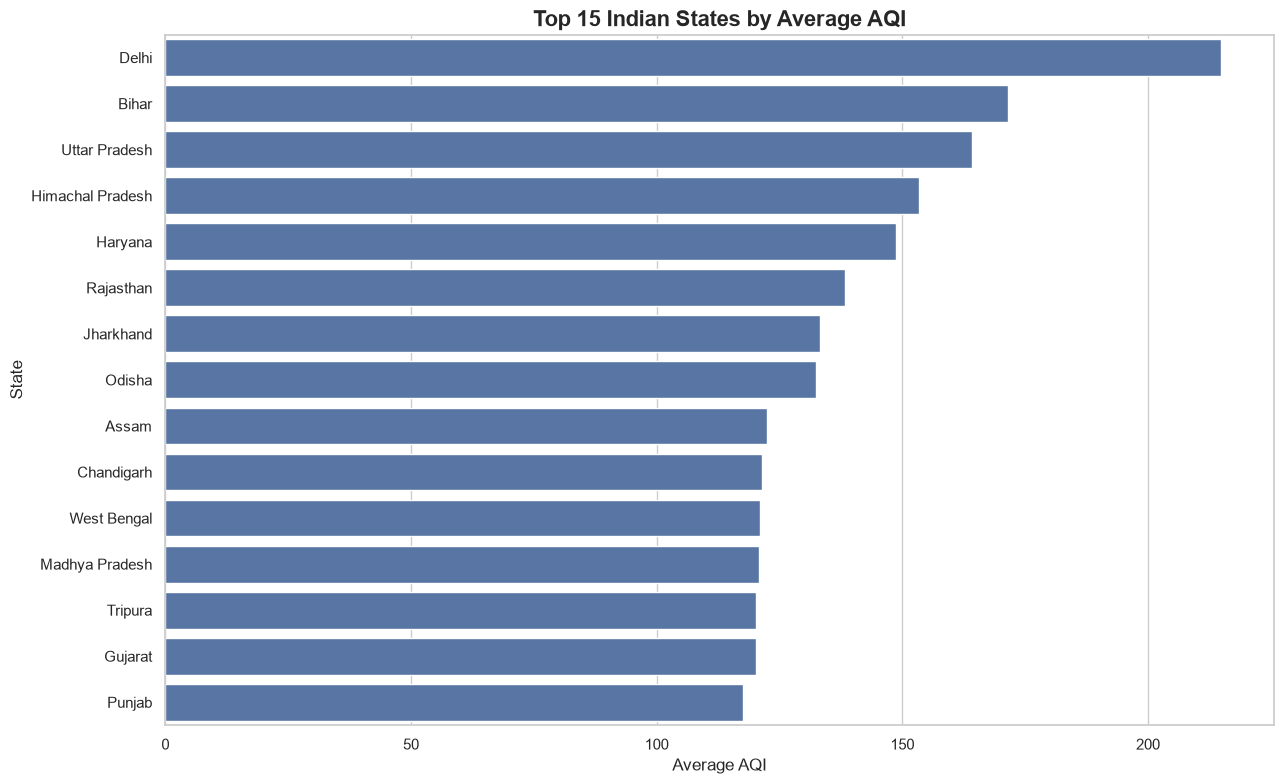

In [20]:
# ==========================================
# 7C. TOP 15 STATES BY AVERAGE AQI
# ==========================================

top_15_states = state_summary.head(15).copy()

plt.figure(figsize=(13, 8))

sns.barplot(
    data=top_15_states,
    x="Average_AQI",
    y="State"
)

plt.title(
    "Top 15 Indian States by Average AQI",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Average AQI")
plt.ylabel("State")

plt.tight_layout()
plt.show()

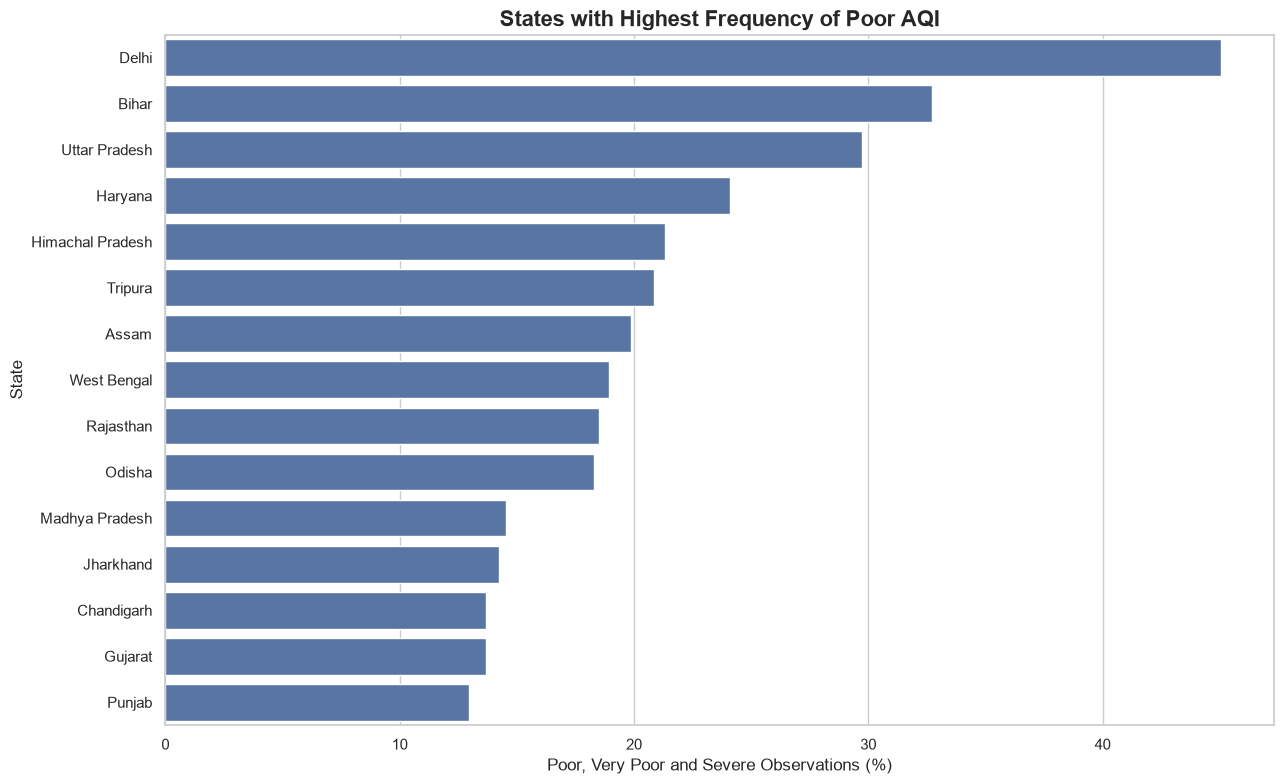

In [21]:
# ==========================================
# 7D. TOP 15 STATES BY POOR AQI FREQUENCY
# ==========================================

top_15_poor_states = state_poor_summary.head(15).copy()

plt.figure(figsize=(13, 8))

sns.barplot(
    data=top_15_poor_states,
    x="Poor_AQI_Percentage",
    y="State"
)

plt.title(
    "States with Highest Frequency of Poor AQI",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Poor, Very Poor and Severe Observations (%)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

## 5. Temporal Analysis

### Objective
Investigate how AQI changes over time across the available
2017–2023 monitoring period.

### Analysis
1. Annual average AQI.
2. Annual median AQI.
3. Percentage of observations with AQI above 200.
4. Monthly AQI trends.
5. Seasonal pollution patterns.

In [22]:
from pathlib import Path
import pandas as pd
import numpy as np

# Define project directory
PROJECT_ROOT = Path.cwd().parent

# Locate processed analytical dataset
ANALYTICAL_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "air_quality_analytical.parquet"
)

# Check file availability
print("File exists:", ANALYTICAL_PATH.exists())

# Load dataset
df_analytical = pd.read_parquet(ANALYTICAL_PATH)

# Verify
print("Dataset shape:", df_analytical.shape)
print("\nColumns:")
print(df_analytical.columns.tolist())

display(df_analytical.head())

File exists: True
Dataset shape: (13509072, 11)

Columns:
['Station ID', 'State', 'City', 'Station Name', 'Date', 'Hour', 'AQI', 'Timestamp', 'Station', 'AQI_Status', 'AQI_Valid']


,Station ID,State,City,Station Name,Date,Hour,AQI,Timestamp,Station,AQI_Status,AQI_Valid
0,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-11,00:00:00,NaN,2017-12-11,Andhra Pradesh | Amaravati | Secretariat Amara...,missing,NaN
1,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-12,00:00:00,263.0,2017-12-12,Andhra Pradesh | Amaravati | Secretariat Amara...,valid,263.0
2,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-13,00:00:00,137.0,2017-12-13,Andhra Pradesh | Amaravati | Secretariat Amara...,valid,137.0
3,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-14,00:00:00,85.0,2017-12-14,Andhra Pradesh | Amaravati | Secretariat Amara...,valid,85.0
4,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-15,00:00:00,127.0,2017-12-15,Andhra Pradesh | Amaravati | Secretariat Amara...,valid,127.0


In [23]:
required_columns = [
    "Timestamp",
    "AQI",
    "AQI_Status",
    "AQI_Valid",
    "Station"
]

for col in required_columns:
    print(f"{col}: {col in df_analytical.columns}")

Timestamp: True
AQI: True
AQI_Status: True
AQI_Valid: True
Station: True


In [24]:
# Extract year from timestamp
df_analytical["Year"] = df_analytical["Timestamp"].dt.year

# Annual AQI summary
annual_aqi = (
    df_analytical
    .dropna(subset=["AQI_Valid"])
    .groupby("Year")
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Minimum_AQI=("AQI_Valid", "min"),
        Maximum_AQI=("AQI_Valid", "max"),
        Valid_Observations=("AQI_Valid", "count"),
        Poor_Observations=(
            "AQI_Valid",
            lambda x: (x > 200).sum()
        )
    )
    .reset_index()
)

annual_aqi["Poor_AQI_Percentage"] = (
    annual_aqi["Poor_Observations"]
    / annual_aqi["Valid_Observations"]
    * 100
)

display(annual_aqi.round(2))

,Year,Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Valid_Observations,Poor_Observations,Poor_AQI_Percentage
0,2017,182.16,133.0,1.0,500.0,240081,85893,35.78
1,2018,169.01,125.0,1.0,500.0,877174,258176,29.43
2,2019,153.18,112.0,1.0,500.0,1368804,346939,25.35
3,2020,129.91,93.0,1.0,500.0,1727659,329924,19.10
4,2021,135.22,97.0,1.0,500.0,2162160,453866,20.99
5,2022,134.66,100.0,1.0,500.0,2573151,531387,20.65
6,2023,124.04,94.0,1.0,500.0,3524456,573434,16.27


### 5.1 Annual AQI Trends

Compare annual average AQI, median AQI, and the
percentage of observations with AQI above 200.

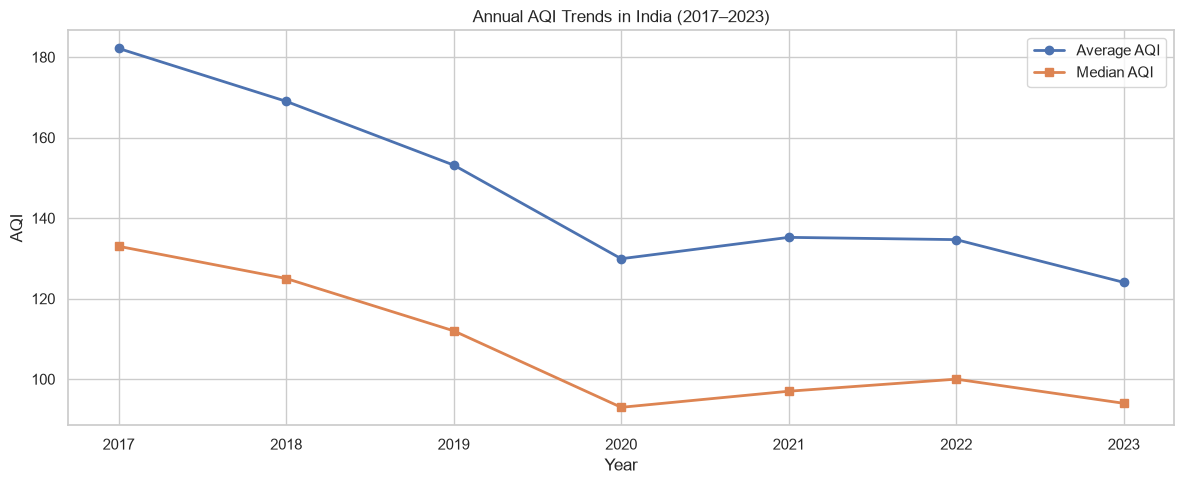

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chart 1: Annual average and median AQI
plt.figure(figsize=(12, 5))

plt.plot(
    annual_aqi["Year"],
    annual_aqi["Average_AQI"],
    marker="o",
    linewidth=2,
    label="Average AQI"
)

plt.plot(
    annual_aqi["Year"],
    annual_aqi["Median_AQI"],
    marker="s",
    linewidth=2,
    label="Median AQI"
)

plt.title("Annual AQI Trends in India (2017–2023)")
plt.xlabel("Year")
plt.ylabel("AQI")
plt.xticks(annual_aqi["Year"])
plt.legend()
plt.tight_layout()
plt.show()

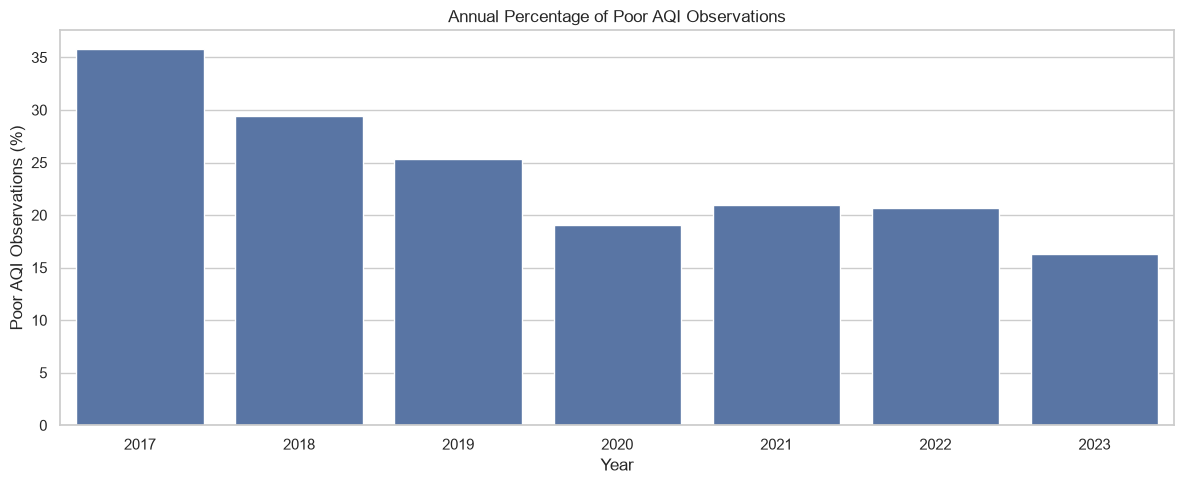

In [26]:
# Chart 2: Percentage of poor AQI observations
plt.figure(figsize=(12, 5))

sns.barplot(
    data=annual_aqi,
    x="Year",
    y="Poor_AQI_Percentage"
)

plt.title("Annual Percentage of Poor AQI Observations")
plt.xlabel("Year")
plt.ylabel("Poor AQI Observations (%)")

plt.tight_layout()
plt.show()

### Annual AQI Trend Analysis (2017–2023)

The annual analysis indicates a declining trend in recorded AQI levels between 2017 and 2023.

**Key findings:**
- Average AQI declined from 182.16 in 2017 to 124.04 in 2023.
- Median AQI decreased from 133 to 94.
- The percentage of Poor, Very Poor, and Severe AQI observations decreased from 35.78% to 16.27%.
- A temporary increase in average AQI and poor AQI frequency was observed in 2021 compared with 2020.
- 2023 recorded the lowest annual average AQI and lowest frequency of poor AQI observations in the dataset.

**Data interpretation caveat:**

The monitoring network expanded substantially during the study period. Active stations increased from 83 in 2017 to 519 in 2023, while active cities increased from 49 to 247. Consequently, annual aggregate comparisons may be influenced by changes in monitoring coverage and geographical representation.

These results describe trends in the available dataset and should not independently be interpreted as proof of nationwide improvement in air quality.

**Next investigation:** Conduct a consistent-station comparison to assess whether the observed decline persists when comparing locations with adequate observations across multiple years.

In [27]:
# Create time-based features

df_analytical["Year"] = df_analytical["Timestamp"].dt.year
df_analytical["Month"] = df_analytical["Timestamp"].dt.month
df_analytical["Month_Name"] = df_analytical["Timestamp"].dt.month_name()
df_analytical["Quarter"] = df_analytical["Timestamp"].dt.quarter

# Define Indian seasonal groups
def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

df_analytical["Season"] = df_analytical["Month"].apply(assign_season)

# Verify
display(
    df_analytical[
        ["Timestamp", "Year", "Month", "Month_Name", "Quarter", "Season"]
    ].head(10)
)

print("\nSeason distribution:")
display(df_analytical["Season"].value_counts())

,Timestamp,Year,Month,Month_Name,Quarter,Season
0,2017-12-11,2017,12,December,4,Winter
1,2017-12-12,2017,12,December,4,Winter
2,2017-12-13,2017,12,December,4,Winter
3,2017-12-14,2017,12,December,4,Winter
4,2017-12-15,2017,12,December,4,Winter
5,2017-12-16,2017,12,December,4,Winter
6,2017-12-17,2017,12,December,4,Winter
7,2017-12-18,2017,12,December,4,Winter
8,2017-12-19,2017,12,December,4,Winter
9,2017-12-20,2017,12,December,4,Winter



Season distribution:


Season
Monsoon         4556496
Winter          3302880
Summer          3195408
Post-Monsoon    2454288
Name: count, dtype: int64

In [28]:
# Monthly AQI summary across all years

monthly_aqi = (
    df_analytical
    .groupby(["Month", "Month_Name"])
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
    .sort_values("Month")
)

monthly_aqi["Average_AQI"] = monthly_aqi["Average_AQI"].round(2)

display(monthly_aqi)

,Month,Month_Name,Average_AQI,Median_AQI,Valid_Observations
0,1,January,195.05,156.0,942758
1,2,February,169.56,132.0,902427
2,3,March,142.56,114.0,1003977
3,4,April,135.02,106.0,947722
4,5,May,121.93,97.0,982195
5,6,June,103.83,82.0,994552
6,7,July,73.05,59.0,1055011
7,8,August,73.49,62.0,1066639
8,9,September,76.03,63.0,1057424
9,10,October,142.19,109.0,1140548


In [29]:
# Seasonal AQI summary

seasonal_aqi = (
    df_analytical
    .groupby("Season")
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
)

season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

seasonal_aqi["Season"] = pd.Categorical(
    seasonal_aqi["Season"],
    categories=season_order,
    ordered=True
)

seasonal_aqi = seasonal_aqi.sort_values("Season")

seasonal_aqi["Average_AQI"] = seasonal_aqi["Average_AQI"].round(2)

display(seasonal_aqi)

,Season,Average_AQI,Median_AQI,Valid_Observations
3,Winter,188.96,149.0,3079692
2,Summer,133.22,106.0,2933894
0,Monsoon,81.25,65.0,4173626
1,Post-Monsoon,170.70,127.0,2286273


In [30]:
print("MONTH WITH HIGHEST AVERAGE AQI")
display(monthly_aqi.nlargest(3, "Average_AQI"))

print("\nMONTH WITH LOWEST AVERAGE AQI")
display(monthly_aqi.nsmallest(3, "Average_AQI"))

print("\nSEASON WITH HIGHEST AVERAGE AQI")
display(seasonal_aqi.nlargest(1, "Average_AQI"))

print("\nSEASON WITH LOWEST AVERAGE AQI")
display(seasonal_aqi.nsmallest(1, "Average_AQI"))

MONTH WITH HIGHEST AVERAGE AQI


,Month,Month_Name,Average_AQI,Median_AQI,Valid_Observations
10,11,November,199.07,158.0,1145725
11,12,December,198.50,161.0,1234507
0,1,January,195.05,156.0,942758



MONTH WITH LOWEST AVERAGE AQI


,Month,Month_Name,Average_AQI,Median_AQI,Valid_Observations
6,7,July,73.05,59.0,1055011
7,8,August,73.49,62.0,1066639
8,9,September,76.03,63.0,1057424



SEASON WITH HIGHEST AVERAGE AQI


,Season,Average_AQI,Median_AQI,Valid_Observations
3,Winter,188.96,149.0,3079692



SEASON WITH LOWEST AVERAGE AQI


,Season,Average_AQI,Median_AQI,Valid_Observations
0,Monsoon,81.25,65.0,4173626


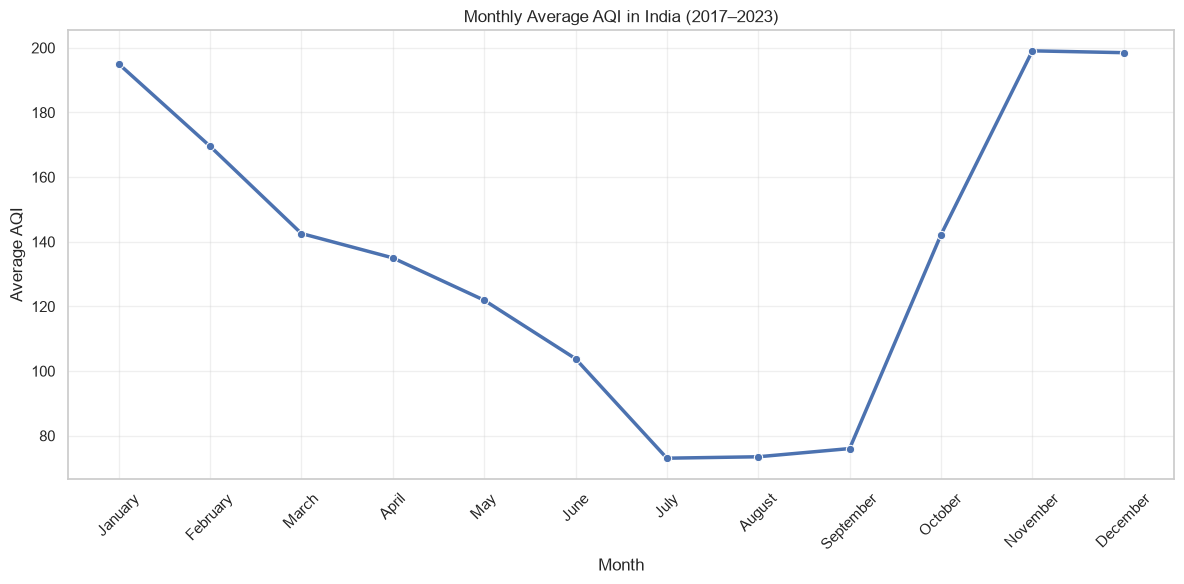

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_aqi,
    x="Month_Name",
    y="Average_AQI",
    marker="o",
    linewidth=2.5
)

plt.title("Monthly Average AQI in India (2017–2023)")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

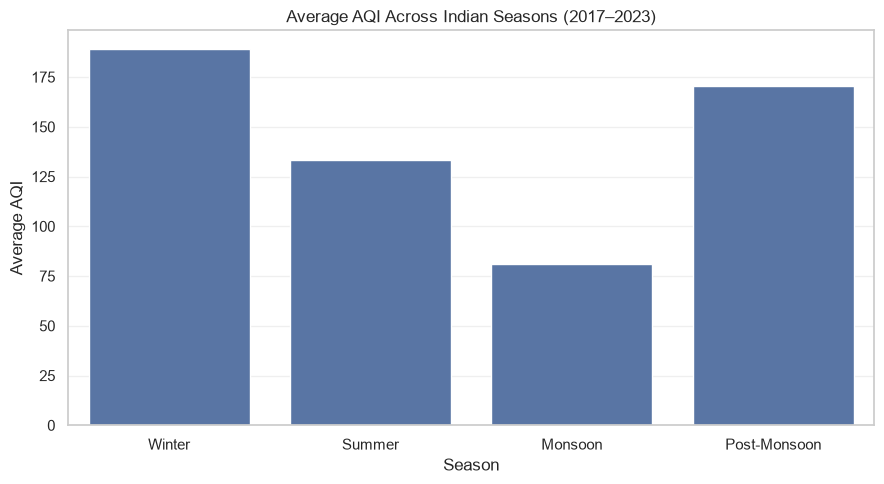

In [32]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=seasonal_aqi,
    x="Season",
    y="Average_AQI"
)

plt.title("Average AQI Across Indian Seasons (2017–2023)")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

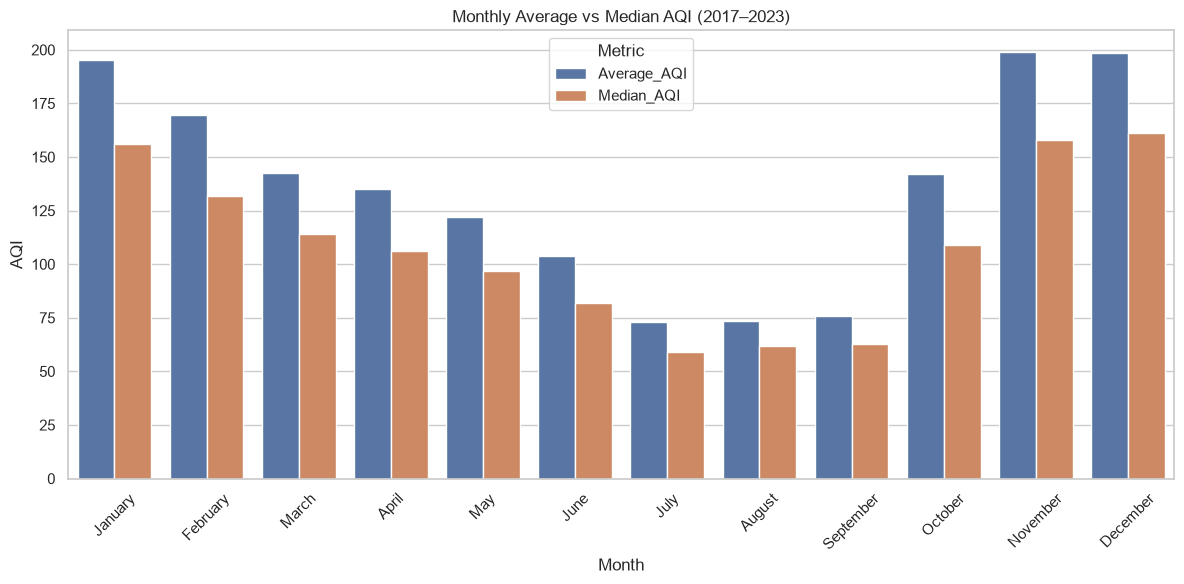

In [33]:
monthly_comparison = monthly_aqi.melt(
    id_vars="Month_Name",
    value_vars=["Average_AQI", "Median_AQI"],
    var_name="Metric",
    value_name="AQI"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_comparison,
    x="Month_Name",
    y="AQI",
    hue="Metric"
)

plt.title("Monthly Average vs Median AQI (2017–2023)")
plt.xlabel("Month")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
# Ensure the seasonal feature is available
df_analytical["Month"] = df_analytical["Timestamp"].dt.month

def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

df_analytical["Season"] = df_analytical["Month"].apply(assign_season)

# Define AQI categories
conditions = [
    df_analytical["AQI_Valid"].between(0, 50),
    df_analytical["AQI_Valid"].between(51, 100),
    df_analytical["AQI_Valid"].between(101, 200),
    df_analytical["AQI_Valid"].between(201, 300),
    df_analytical["AQI_Valid"].between(301, 400),
    df_analytical["AQI_Valid"].between(401, 500)
]

categories = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

df_analytical["AQI_Category"] = np.select(
    conditions,
    categories,
    default="Unclassified"
)

# Seasonal AQI category distribution
season_category = pd.crosstab(
    df_analytical["Season"],
    df_analytical["AQI_Category"],
    normalize="index"
) * 100

season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

season_category = season_category.reindex(season_order)

display(season_category.round(2))

AQI_Category,Good,Moderate,Poor,Satisfactory,Severe,Unclassified,Very Poor
Season,,,,,,,
Winter,6.17,30.24,12.03,21.61,6.19,6.76,17.01
Summer,11.33,33.50,8.34,30.81,2.04,8.18,5.80
Monsoon,31.41,19.05,2.39,37.17,0.61,8.40,0.97
Post-Monsoon,11.47,29.32,10.22,23.10,6.22,6.85,12.84


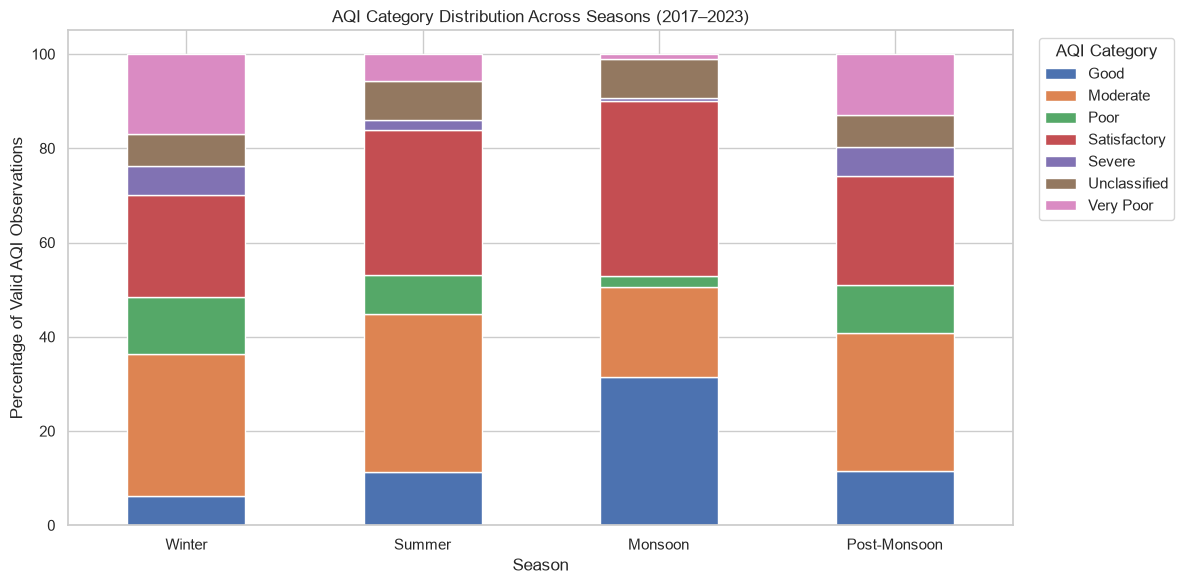

In [35]:
import matplotlib.pyplot as plt

season_category.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("AQI Category Distribution Across Seasons (2017–2023)")
plt.xlabel("Season")
plt.ylabel("Percentage of Valid AQI Observations")
plt.xticks(rotation=0)
plt.legend(title="AQI Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [36]:
# Keep only observations with valid AQI values
df_valid = df_analytical[
    df_analytical["AQI_Valid"].notna()
].copy()

# Assign official AQI categories
conditions = [
    df_valid["AQI_Valid"].between(0, 50),
    df_valid["AQI_Valid"].between(51, 100),
    df_valid["AQI_Valid"].between(101, 200),
    df_valid["AQI_Valid"].between(201, 300),
    df_valid["AQI_Valid"].between(301, 400),
    df_valid["AQI_Valid"].between(401, 500)
]

categories = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

df_valid["AQI_Category"] = np.select(
    conditions,
    categories,
    default="Unclassified"
)

# Define category and seasonal order
category_order = [
    "Good", "Satisfactory", "Moderate",
    "Poor", "Very Poor", "Severe"
]

season_order = [
    "Winter", "Summer", "Monsoon", "Post-Monsoon"
]

# Calculate seasonal distribution
season_category_corrected = pd.crosstab(
    df_valid["Season"],
    df_valid["AQI_Category"],
    normalize="index"
) * 100

season_category_corrected = season_category_corrected.reindex(
    index=season_order,
    columns=category_order,
    fill_value=0
)

display(season_category_corrected.round(2))

# Check that every season adds up to 100%
print("\nPercentage total by season:")
display(season_category_corrected.sum(axis=1).round(2))

AQI_Category,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
Season,,,,,,
Winter,6.62,23.17,32.43,12.90,18.24,6.64
Summer,12.34,33.55,36.49,9.08,6.32,2.22
Monsoon,34.29,40.58,20.80,2.61,1.06,0.66
Post-Monsoon,12.31,24.80,31.47,10.97,13.78,6.68



Percentage total by season:


Season
Winter          100.0
Summer          100.0
Monsoon         100.0
Post-Monsoon    100.0
dtype: float64

In [37]:
# Extract hour from timestamp
df_valid["Hour_Number"] = df_valid["Timestamp"].dt.hour

# Hourly AQI summary
hourly_aqi = (
    df_valid.groupby("Hour_Number")
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
)

display(hourly_aqi.round(2))

,Hour_Number,Average_AQI,Median_AQI,Valid_Observations
0,0,154.43,110.0,522432
1,1,149.95,106.0,507662
2,2,143.75,101.0,514220
3,3,138.54,97.0,512975
4,4,134.17,93.0,510899
5,5,131.37,91.0,511945
6,6,130.51,90.0,509257
7,7,132.90,93.0,510915
8,8,140.02,100.0,509703
9,9,147.24,104.0,512617


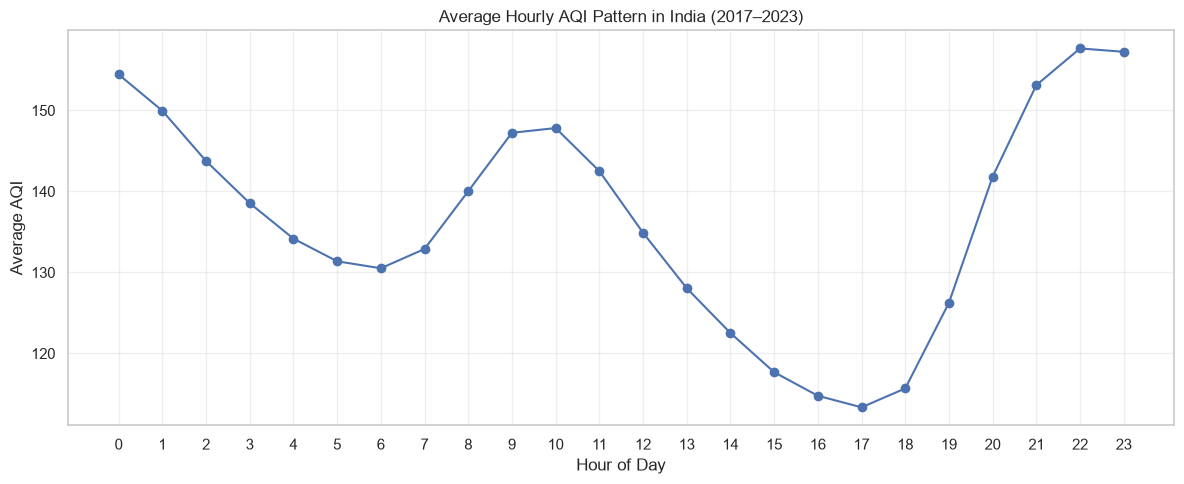

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_aqi["Hour_Number"],
    hourly_aqi["Average_AQI"],
    marker="o"
)

plt.xticks(range(24))
plt.xlabel("Hour of Day")
plt.ylabel("Average AQI")
plt.title("Average Hourly AQI Pattern in India (2017–2023)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

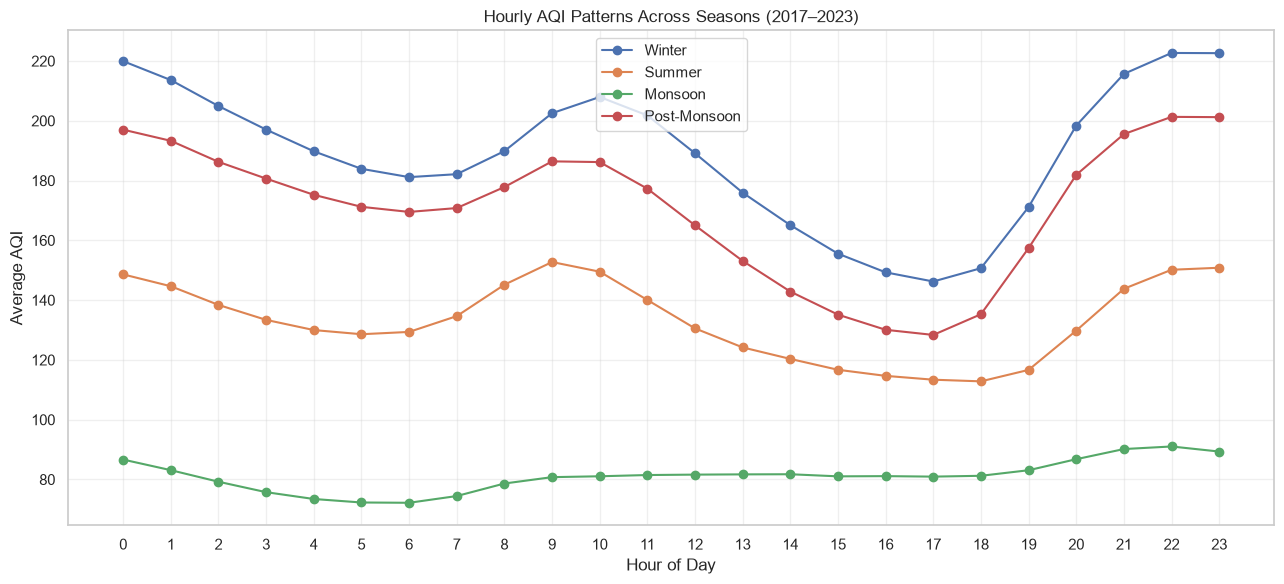

In [39]:
seasonal_hourly_aqi = (
    df_valid.groupby(["Season", "Hour_Number"])["AQI_Valid"]
    .mean()
    .reset_index(name="Average_AQI")
)

season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

plt.figure(figsize=(13, 6))

for season in season_order:
    season_data = seasonal_hourly_aqi[
        seasonal_hourly_aqi["Season"] == season
    ]

    plt.plot(
        season_data["Hour_Number"],
        season_data["Average_AQI"],
        marker="o",
        label=season
    )

plt.xticks(range(24))
plt.xlabel("Hour of Day")
plt.ylabel("Average AQI")
plt.title("Hourly AQI Patterns Across Seasons (2017–2023)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
# State-level AQI analysis

state_aqi = (
    df_analytical
    .dropna(subset=["AQI_Valid"])
    .groupby("State")
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Minimum_AQI=("AQI_Valid", "min"),
        Maximum_AQI=("AQI_Valid", "max"),
        Valid_Observations=("AQI_Valid", "count"),
        Cities=("City", "nunique"),
        Stations=("Station", "nunique")
    )
    .reset_index()
)

# Round numerical values
state_aqi["Average_AQI"] = state_aqi["Average_AQI"].round(2)
state_aqi["Median_AQI"] = state_aqi["Median_AQI"].round(2)

# Sort from highest to lowest average AQI
state_aqi = state_aqi.sort_values(
    by="Average_AQI",
    ascending=False
)

display(state_aqi)

,State,Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Valid_Observations,Cities,Stations
6,Delhi,214.90,178.0,1.0,500.0,1777818,1,39
3,Bihar,171.47,130.0,1.0,500.0,705784,20,30
26,Uttar Pradesh,164.23,123.0,1.0,500.0,1405354,18,49
9,Himachal Pradesh,153.29,127.0,1.0,500.0,14842,1,1
8,Haryana,148.66,113.0,1.0,500.0,1826127,22,67
21,Rajasthan,138.34,109.0,1.0,500.0,568727,26,35
11,Jharkhand,133.20,114.0,1.0,500.0,28863,3,3
19,Odisha,132.38,106.0,1.0,500.0,171336,16,19
2,Assam,122.40,78.0,1.0,500.0,123764,6,9
4,Chandigarh,121.39,101.0,2.0,500.0,73086,1,3


In [41]:
state_aqi_reliable = state_aqi[
    state_aqi["Valid_Observations"] >= 10000
].copy()

print("States meeting the observation threshold:",
      len(state_aqi_reliable))

print("\nTop 10 states by average AQI:")
display(state_aqi_reliable.head(10))

print("\nBottom 10 states by average AQI:")
display(state_aqi_reliable.tail(10))

States meeting the observation threshold: 29

Top 10 states by average AQI:


,State,Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Valid_Observations,Cities,Stations
6,Delhi,214.90,178.0,1.0,500.0,1777818,1,39
3,Bihar,171.47,130.0,1.0,500.0,705784,20,30
26,Uttar Pradesh,164.23,123.0,1.0,500.0,1405354,18,49
9,Himachal Pradesh,153.29,127.0,1.0,500.0,14842,1,1
8,Haryana,148.66,113.0,1.0,500.0,1826127,22,67
21,Rajasthan,138.34,109.0,1.0,500.0,568727,26,35
11,Jharkhand,133.20,114.0,1.0,500.0,28863,3,3
19,Odisha,132.38,106.0,1.0,500.0,171336,16,19
2,Assam,122.40,78.0,1.0,500.0,123764,6,9
4,Chandigarh,121.39,101.0,2.0,500.0,73086,1,3



Bottom 10 states by average AQI:


,State,Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Valid_Observations,Cities,Stations
0,Andhra Pradesh,86.88,71.0,1.0,500.0,215037,8,11
10,Jammu and Kashmir,81.48,64.0,4.0,500.0,20025,1,1
5,Chhattisgarh,77.53,66.0,1.0,500.0,105052,8,13
23,Tamil Nadu,74.58,62.0,1.0,500.0,426798,16,26
12,Karnataka,69.66,58.0,1.0,500.0,1006949,23,38
13,Kerala,68.18,61.0,1.0,500.0,273350,8,9
1,Arunachal Pradesh,55.32,43.0,2.0,490.0,10037,1,1
22,Sikkim,48.98,50.0,9.0,500.0,13858,1,1
17,Meghalaya,47.13,32.0,3.0,500.0,35360,1,2
18,Mizoram,41.53,27.0,4.0,500.0,28059,1,1


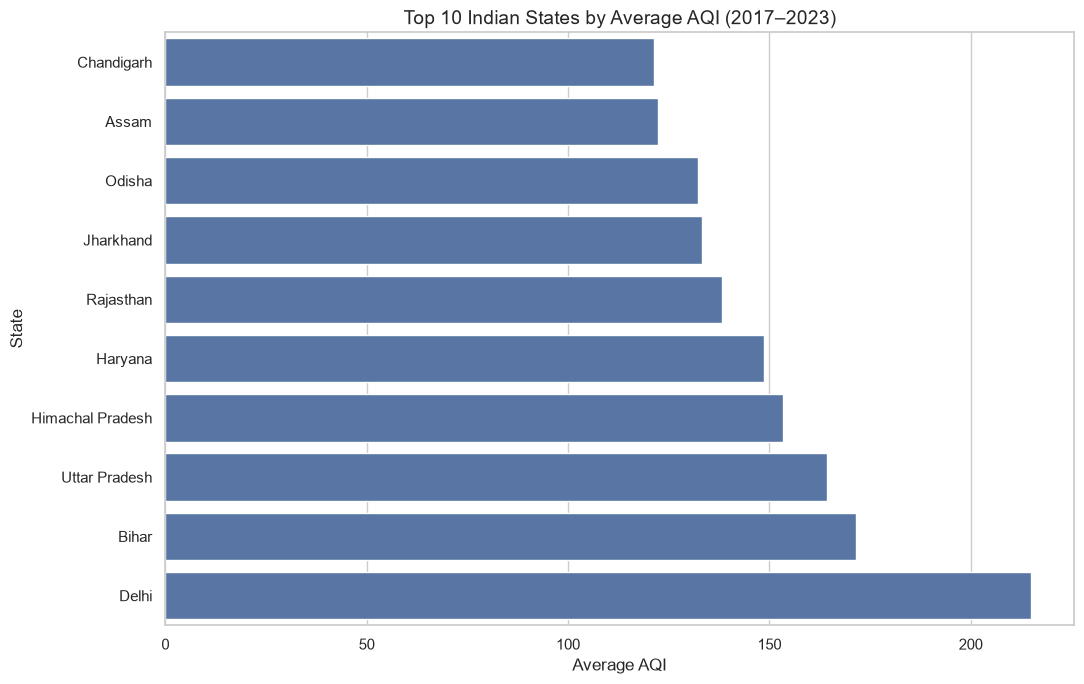

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Top 10 states
top_states = state_aqi_reliable.head(10).sort_values(
    "Average_AQI",
    ascending=True
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_states,
    x="Average_AQI",
    y="State"
)

plt.title(
    "Top 10 Indian States by Average AQI (2017–2023)",
    fontsize=14
)
plt.xlabel("Average AQI")
plt.ylabel("State")
plt.tight_layout()
plt.show()

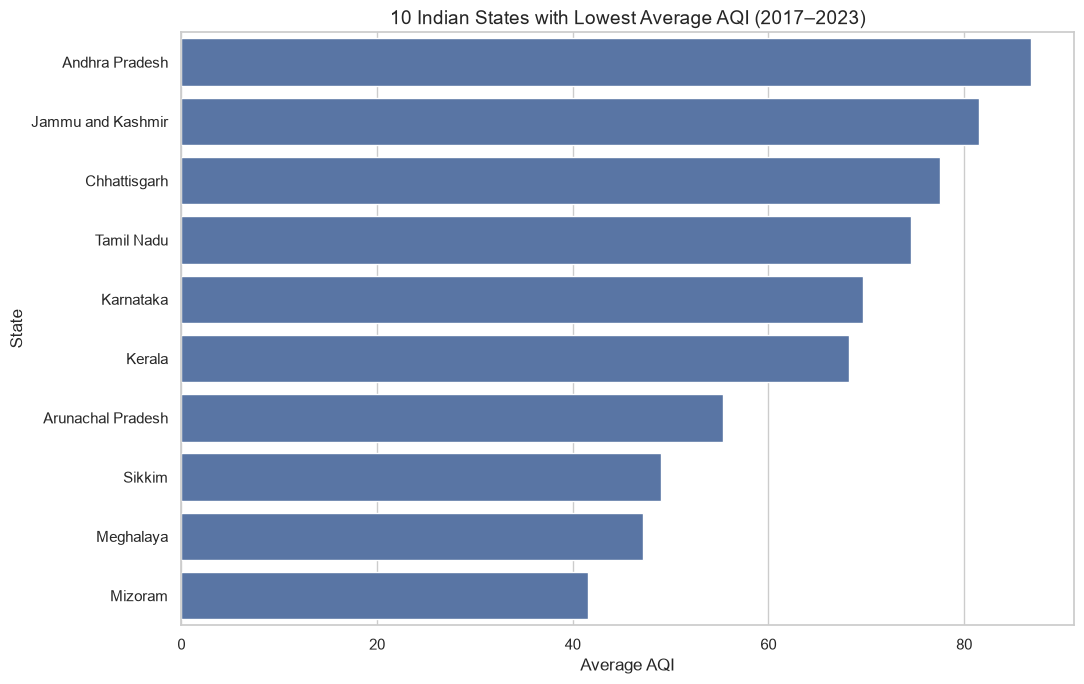

In [43]:
bottom_states = state_aqi_reliable.tail(10).sort_values(
    "Average_AQI",
    ascending=False
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=bottom_states,
    x="Average_AQI",
    y="State"
)

plt.title(
    "10 Indian States with Lowest Average AQI (2017–2023)",
    fontsize=14
)
plt.xlabel("Average AQI")
plt.ylabel("State")
plt.tight_layout()
plt.show()

## State-Level AQI Analysis — Key Findings

1. Delhi recorded the highest average AQI (214.90), followed by Bihar (171.47) and Uttar Pradesh (164.23).
2. Mizoram (41.53), Meghalaya (47.13), and Sikkim (48.98) recorded the lowest average AQI.
3. Considerable geographical variation exists in observed AQI levels across Indian states.
4. State-level comparisons are affected by differences in monitoring station coverage and observation counts.
5. These results are descriptive and should not be interpreted as definitive state-wide rankings.

### Analytical Limitation
The dataset has an expanding monitoring network over 2017–2023.
Further analysis should account for station coverage, observation volume,
and differences in the number of monitored cities and stations.

In [44]:
# City-level AQI aggregation

city_aqi = (
    df_analytical
    .dropna(subset=["AQI_Valid"])
    .groupby(["State", "City"])
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Minimum_AQI=("AQI_Valid", "min"),
        Maximum_AQI=("AQI_Valid", "max"),
        Valid_Observations=("AQI_Valid", "count"),
        Stations=("Station Name", "nunique")
    )
    .reset_index()
)

# Round AQI statistics
city_aqi[
    ["Average_AQI", "Median_AQI", "Minimum_AQI", "Maximum_AQI"]
] = city_aqi[
    ["Average_AQI", "Median_AQI", "Minimum_AQI", "Maximum_AQI"]
].round(2)

print("Total cities:", len(city_aqi))
print("\nCity-level summary:")
display(city_aqi.head(10))

Total cities: 248

City-level summary:


,State,City,Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Valid_Observations,Stations
0,Andhra Pradesh,Amaravati,78.15,62.0,1.0,500.0,48401,1
1,Andhra Pradesh,Anantapur,66.78,60.0,16.0,500.0,10636,1
2,Andhra Pradesh,Chittoor,70.99,58.0,1.0,500.0,7413,1
3,Andhra Pradesh,Kadapa,68.88,49.0,6.0,500.0,7573,1
4,Andhra Pradesh,Rajamahendravaram,84.48,68.0,4.0,500.0,51461,1
5,Andhra Pradesh,Tirupati,72.34,57.0,7.0,500.0,8284,1
6,Andhra Pradesh,Vijayawada,74.15,64.0,1.0,500.0,27646,4
7,Andhra Pradesh,Visakhapatnam,114.62,101.0,2.0,500.0,53623,1
8,Arunachal Pradesh,Naharlagun,55.32,43.0,2.0,490.0,10037,1
9,Assam,Byrnihat,233.83,177.0,2.0,500.0,7825,1


In [45]:
# Minimum data requirement for city-level comparison
MIN_OBSERVATIONS = 10000

city_aqi_filtered = city_aqi[
    city_aqi["Valid_Observations"] >= MIN_OBSERVATIONS
].copy()

# Sort cities by average AQI
city_aqi_sorted = city_aqi_filtered.sort_values(
    "Average_AQI",
    ascending=False
)

# Top 10 cities with highest average AQI
top_10_cities = city_aqi_sorted.head(10)

# Top 10 cities with lowest average AQI
bottom_10_cities = city_aqi_sorted.tail(10).sort_values(
    "Average_AQI",
    ascending=True
)

print("Total cities before filtering:", len(city_aqi))
print("Cities meeting observation threshold:", len(city_aqi_filtered))
print("Cities excluded:", len(city_aqi) - len(city_aqi_filtered))

print("\nTOP 10 CITIES BY AVERAGE AQI")
display(
    top_10_cities[
        ["State", "City", "Average_AQI",
         "Median_AQI", "Valid_Observations", "Stations"]
    ].reset_index(drop=True)
)

print("\nBOTTOM 10 CITIES BY AVERAGE AQI")
display(
    bottom_10_cities[
        ["State", "City", "Average_AQI",
         "Median_AQI", "Valid_Observations", "Stations"]
    ].reset_index(drop=True)
)

Total cities before filtering: 248
Cities meeting observation threshold: 168
Cities excluded: 80

TOP 10 CITIES BY AVERAGE AQI


,State,City,Average_AQI,Median_AQI,Valid_Observations,Stations
0,Uttar Pradesh,Ghaziabad,222.28,186.0,132892,3
1,Rajasthan,Bhiwadi,220.82,195.0,48913,1
2,Delhi,Delhi,214.90,178.0,1777818,39
3,Uttar Pradesh,Noida,210.92,173.0,254860,6
4,Bihar,Katihar,208.74,160.0,17036,1
5,Bihar,Saharsa,204.75,173.0,15764,1
6,Haryana,Faridabad,202.00,167.0,131396,4
7,Uttar Pradesh,Baghpat,201.67,167.0,39614,2
8,Bihar,Darbhanga,200.38,157.0,10183,1
9,Bihar,Siwan,200.18,155.0,16465,1



BOTTOM 10 CITIES BY AVERAGE AQI


,State,City,Average_AQI,Median_AQI,Valid_Observations,Stations
0,Assam,Sivasagar,39.47,33.0,10690,1
1,Mizoram,Aizawl,41.53,27.0,28059,1
2,Karnataka,Madikeri,43.59,38.0,26324,1
3,Karnataka,Chamarajanagar,45.73,42.0,26282,1
4,Meghalaya,Shillong,47.13,32.0,35360,2
5,Sikkim,Gangtok,48.98,50.0,13858,1
6,Karnataka,Chikkamagaluru,50.23,44.0,30153,1
7,Karnataka,Bagalkot,52.49,46.0,30978,1
8,Karnataka,Mysuru,53.62,50.0,34221,1
9,Tamil Nadu,Ramanathapuram,53.97,44.0,10980,1


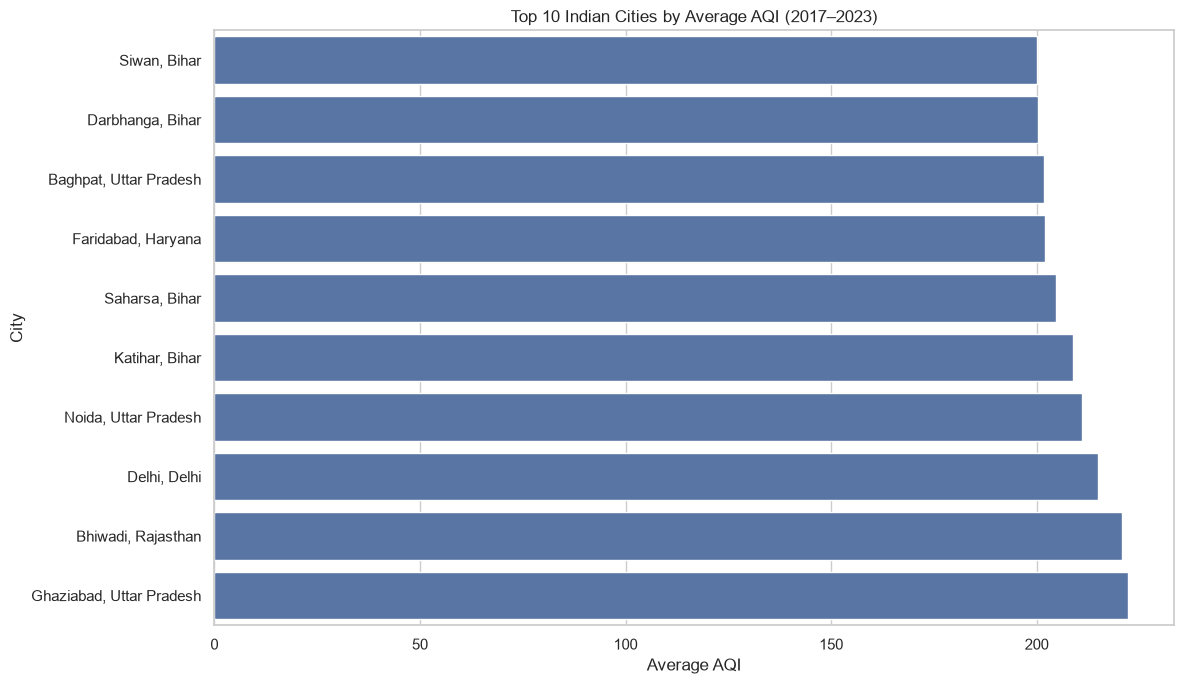

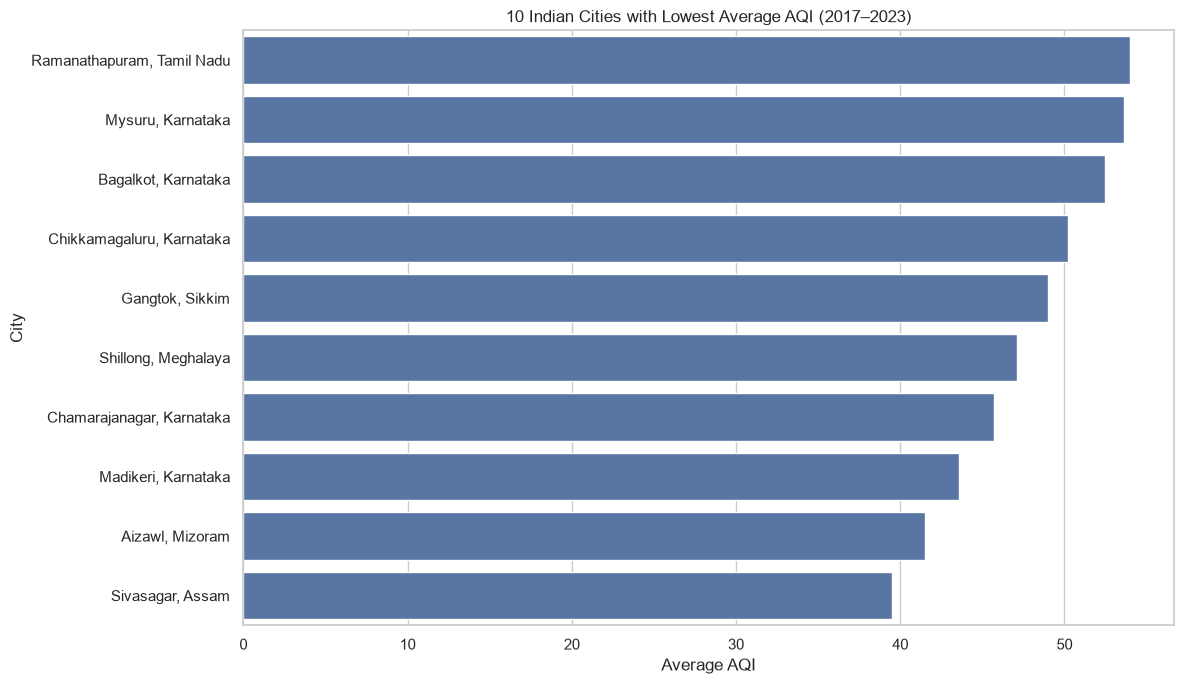

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Create city labels with state names
top_10_cities = top_10_cities.copy()
bottom_10_cities = bottom_10_cities.copy()

top_10_cities["City_Label"] = (
    top_10_cities["City"] + ", " + top_10_cities["State"]
)

bottom_10_cities["City_Label"] = (
    bottom_10_cities["City"] + ", " + bottom_10_cities["State"]
)

# Chart 1: Highest AQI cities
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_cities.sort_values("Average_AQI"),
    x="Average_AQI",
    y="City_Label"
)

plt.title("Top 10 Indian Cities by Average AQI (2017–2023)")
plt.xlabel("Average AQI")
plt.ylabel("City")

plt.tight_layout()
plt.show()


# Chart 2: Lowest AQI cities
plt.figure(figsize=(12, 7))

sns.barplot(
    data=bottom_10_cities.sort_values("Average_AQI", ascending=False),
    x="Average_AQI",
    y="City_Label"
)

plt.title("10 Indian Cities with Lowest Average AQI (2017–2023)")
plt.xlabel("Average AQI")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [47]:
# Save city-level analytical results
city_output_path = (
    PROJECT_ROOT / "data" / "processed" / "city_aqi_summary.csv"
)

city_aqi.to_csv(city_output_path, index=False)

print("City-level summary saved successfully!")
print("File:", city_output_path)

City-level summary saved successfully!
File: c:\Users\khush\Projects\india-air-quality-intelligence\data\processed\city_aqi_summary.csv


In [48]:
# Select the top 10 cities identified in the previous analysis
top_city_pairs = top_10_cities[["State", "City"]].drop_duplicates()

# Filter observations for these cities
top_city_mask = pd.Series(False, index=df_analytical.index)

for _, city_row in top_city_pairs.iterrows():
    top_city_mask |= (
        (df_analytical["State"] == city_row["State"]) &
        (df_analytical["City"] == city_row["City"])
    )

top_city_data = df_analytical.loc[
    top_city_mask,
    ["State", "City", "Timestamp", "AQI_Valid"]
].copy()

# Extract year
top_city_data["Year"] = top_city_data["Timestamp"].dt.year

# Calculate yearly AQI statistics
city_yearly_aqi = (
    top_city_data
    .dropna(subset=["AQI_Valid"])
    .groupby(["State", "City", "Year"])
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
)

city_yearly_aqi["Average_AQI"] = (
    city_yearly_aqi["Average_AQI"].round(2)
)

print("Yearly city-level records:", len(city_yearly_aqi))

display(
    city_yearly_aqi.sort_values(
        ["City", "Year"]
    ).reset_index(drop=True)
)

Yearly city-level records: 53


,State,City,Year,Average_AQI,Median_AQI,Valid_Observations
0,Uttar Pradesh,Baghpat,2018,243.91,262.0,3664
1,Uttar Pradesh,Baghpat,2019,218.06,190.0,8508
2,Uttar Pradesh,Baghpat,2020,211.28,168.0,4818
3,Uttar Pradesh,Baghpat,2021,212.67,186.0,8156
4,Uttar Pradesh,Baghpat,2022,162.81,130.0,6785
5,Uttar Pradesh,Baghpat,2023,179.99,145.0,7683
6,Rajasthan,Bhiwadi,2017,386.54,382.5,998
7,Rajasthan,Bhiwadi,2018,273.60,283.0,6882
8,Rajasthan,Bhiwadi,2019,223.72,204.0,7918
9,Rajasthan,Bhiwadi,2020,191.85,155.0,8185


In [49]:
# Identify cities with sufficient observations in every year

MIN_OBSERVATIONS = 3000
EXPECTED_YEARS = set(range(2017, 2024))

# Check yearly coverage for each State-City combination
city_year_coverage = (
    city_yearly_aqi
    .groupby(["State", "City"])
    .agg(
        Years_Available=("Year", "nunique"),
        Minimum_Yearly_Observations=("Valid_Observations", "min"),
        Total_Observations=("Valid_Observations", "sum")
    )
    .reset_index()
)

# Identify eligible cities
eligible_cities = city_year_coverage[
    (city_year_coverage["Years_Available"] == len(EXPECTED_YEARS)) &
    (city_year_coverage["Minimum_Yearly_Observations"] >= MIN_OBSERVATIONS)
][["State", "City"]]

print("Cities eligible for year-on-year comparison:", len(eligible_cities))

display(eligible_cities)

# Create balanced comparison dataset
balanced_city_trends = city_yearly_aqi.merge(
    eligible_cities,
    on=["State", "City"],
    how="inner"
)

balanced_city_trends = balanced_city_trends.sort_values(
    ["State", "City", "Year"]
).reset_index(drop=True)

print("\nBalanced dataset shape:", balanced_city_trends.shape)

display(balanced_city_trends)

Cities eligible for year-on-year comparison: 4


,State,City
4,Delhi,Delhi
5,Haryana,Faridabad
8,Uttar Pradesh,Ghaziabad
9,Uttar Pradesh,Noida



Balanced dataset shape: (28, 6)


,State,City,Year,Average_AQI,Median_AQI,Valid_Observations
0,Delhi,Delhi,2017,242.43,257.0,67329
1,Delhi,Delhi,2018,231.83,203.0,242993
2,Delhi,Delhi,2019,219.36,185.0,290334
3,Delhi,Delhi,2020,191.64,145.0,292441
4,Delhi,Delhi,2021,214.21,172.0,293029
5,Delhi,Delhi,2022,216.95,189.0,297025
6,Delhi,Delhi,2023,211.98,167.0,294667
7,Haryana,Faridabad,2017,231.58,233.0,5871
8,Haryana,Faridabad,2018,226.33,210.0,8300
9,Haryana,Faridabad,2019,191.62,153.0,7666


In [50]:
# Calculate year-on-year AQI changes for each eligible city

balanced_city_trends = balanced_city_trends.sort_values(
    ["State", "City", "Year"]
).copy()

# Previous year's average AQI
balanced_city_trends["Previous_Year_AQI"] = (
    balanced_city_trends
    .groupby(["State", "City"])["Average_AQI"]
    .shift(1)
)

# Absolute AQI change
balanced_city_trends["AQI_Change"] = (
    balanced_city_trends["Average_AQI"]
    - balanced_city_trends["Previous_Year_AQI"]
)

# Percentage AQI change
balanced_city_trends["AQI_Change_Percentage"] = (
    balanced_city_trends["AQI_Change"]
    / balanced_city_trends["Previous_Year_AQI"]
) * 100

# Round results
balanced_city_trends[
    ["AQI_Change", "AQI_Change_Percentage"]
] = balanced_city_trends[
    ["AQI_Change", "AQI_Change_Percentage"]
].round(2)

# Display results
display(
    balanced_city_trends[
        [
            "State",
            "City",
            "Year",
            "Average_AQI",
            "Previous_Year_AQI",
            "AQI_Change",
            "AQI_Change_Percentage"
        ]
    ].reset_index(drop=True)
)

,State,City,Year,Average_AQI,Previous_Year_AQI,AQI_Change,AQI_Change_Percentage
0,Delhi,Delhi,2017,242.43,NaN,NaN,NaN
1,Delhi,Delhi,2018,231.83,242.43,-10.60,-4.37
2,Delhi,Delhi,2019,219.36,231.83,-12.47,-5.38
3,Delhi,Delhi,2020,191.64,219.36,-27.72,-12.64
4,Delhi,Delhi,2021,214.21,191.64,22.57,11.78
5,Delhi,Delhi,2022,216.95,214.21,2.74,1.28
6,Delhi,Delhi,2023,211.98,216.95,-4.97,-2.29
7,Haryana,Faridabad,2017,231.58,NaN,NaN,NaN
8,Haryana,Faridabad,2018,226.33,231.58,-5.25,-2.27
9,Haryana,Faridabad,2019,191.62,226.33,-34.71,-15.34


## Year-on-Year AQI Trend Comparison

This section compares annual average AQI trends across four cities
with sufficient observations in every year from 2017 to 2023.

The objective is to identify long-term patterns, annual fluctuations,
and differences in pollution trends across cities.

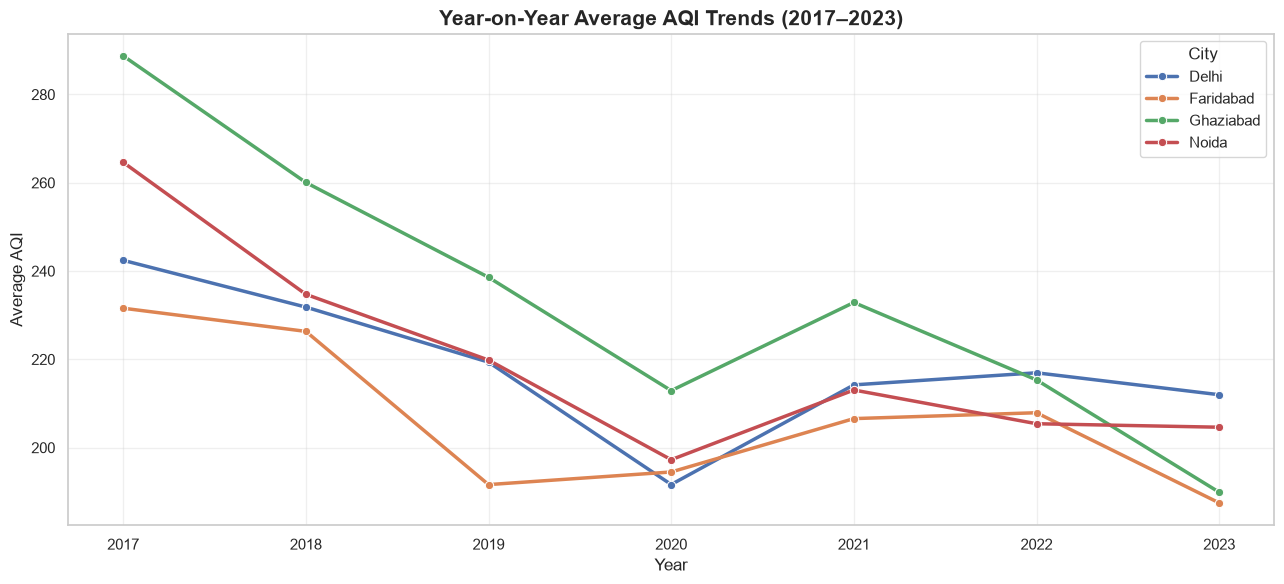

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=balanced_city_trends,
    x="Year",
    y="Average_AQI",
    hue="City",
    marker="o",
    linewidth=2.5
)

plt.title(
    "Year-on-Year Average AQI Trends (2017–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Average AQI", fontsize=12)

plt.xticks(range(2017, 2024))
plt.grid(True, alpha=0.3)
plt.legend(title="City")
plt.tight_layout()

plt.show()

In [52]:
# Compare the first and last year for each city

city_change_summary = (
    balanced_city_trends
    .pivot(
        index=["State", "City"],
        columns="Year",
        values="Average_AQI"
    )
    .reset_index()
)

city_change_summary["AQI_Change_2017_2023"] = (
    city_change_summary[2023] - city_change_summary[2017]
)

city_change_summary["AQI_Change_Percentage"] = (
    city_change_summary["AQI_Change_2017_2023"]
    / city_change_summary[2017]
) * 100

city_change_summary = city_change_summary.sort_values(
    "AQI_Change_Percentage"
)

display(city_change_summary.round(2))

Year,State,City,2017,2018,2019,2020,2021,2022,2023,AQI_Change_2017_2023,AQI_Change_Percentage
2,Uttar Pradesh,Ghaziabad,288.75,260.06,238.58,212.91,232.88,215.33,189.89,-98.86,-34.24
3,Uttar Pradesh,Noida,264.63,234.73,219.83,197.26,213.05,205.41,204.62,-60.01,-22.68
1,Haryana,Faridabad,231.58,226.33,191.62,194.48,206.57,207.90,187.47,-44.11,-19.05
0,Delhi,Delhi,242.43,231.83,219.36,191.64,214.21,216.95,211.98,-30.45,-12.56


### Key Insights

1. Ghaziabad recorded the largest reduction in average AQI
   between 2017 and 2023, declining by approximately 34.24%.

2. Noida and Faridabad recorded reductions of 22.68% and
   19.05%, respectively.

3. Delhi recorded the smallest reduction among the four
   cities, with average AQI declining by approximately 12.56%.

4. All four cities experienced a decrease in average AQI
   between 2017 and 2020, followed by an increase in 2021.

5. AQI trends varied across cities after 2020, indicating
   that pollution patterns were not uniform across the region.

### Analytical Limitation

These findings are descriptive and do not establish causal
relationships. Changes in monitoring station coverage,
data availability, and observation patterns may influence
yearly comparisons. The results should therefore not be
interpreted as definitive evidence of the impact of
environmental policies or interventions.

In [53]:
print("Available columns:")
print(df_analytical.columns.tolist())

print("\nTimestamp data type:")
print(df_analytical["Timestamp"].dtype)

print("\nDate range:")
print(df_analytical["Timestamp"].min())
print(df_analytical["Timestamp"].max())

Available columns:
['Station ID', 'State', 'City', 'Station Name', 'Date', 'Hour', 'AQI', 'Timestamp', 'Station', 'AQI_Status', 'AQI_Valid', 'Year', 'Month', 'Month_Name', 'Quarter', 'Season', 'AQI_Category']

Timestamp data type:
datetime64[us]

Date range:
2017-01-01 00:00:00
2023-12-31 23:00:00


## Monthly AQI Trend Analysis

This section examines monthly variations in air quality across
the 2017–2023 period.

The objective is to identify months with consistently higher
or lower average AQI and understand recurring seasonal patterns.

Only valid AQI observations are included in the calculations.

In [54]:
monthly_aqi = (
    df_analytical
    .dropna(subset=["AQI_Valid"])
    .groupby("Month")
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
)

monthly_aqi["Month_Name"] = monthly_aqi["Month"].map({
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
})

monthly_aqi["Average_AQI"] = monthly_aqi["Average_AQI"].round(2)

display(monthly_aqi)

,Month,Average_AQI,Median_AQI,Valid_Observations,Month_Name
0,1,195.05,156.0,942758,January
1,2,169.56,132.0,902427,February
2,3,142.56,114.0,1003977,March
3,4,135.02,106.0,947722,April
4,5,121.93,97.0,982195,May
5,6,103.83,82.0,994552,June
6,7,73.05,59.0,1055011,July
7,8,73.49,62.0,1066639,August
8,9,76.03,63.0,1057424,September
9,10,142.19,109.0,1140548,October


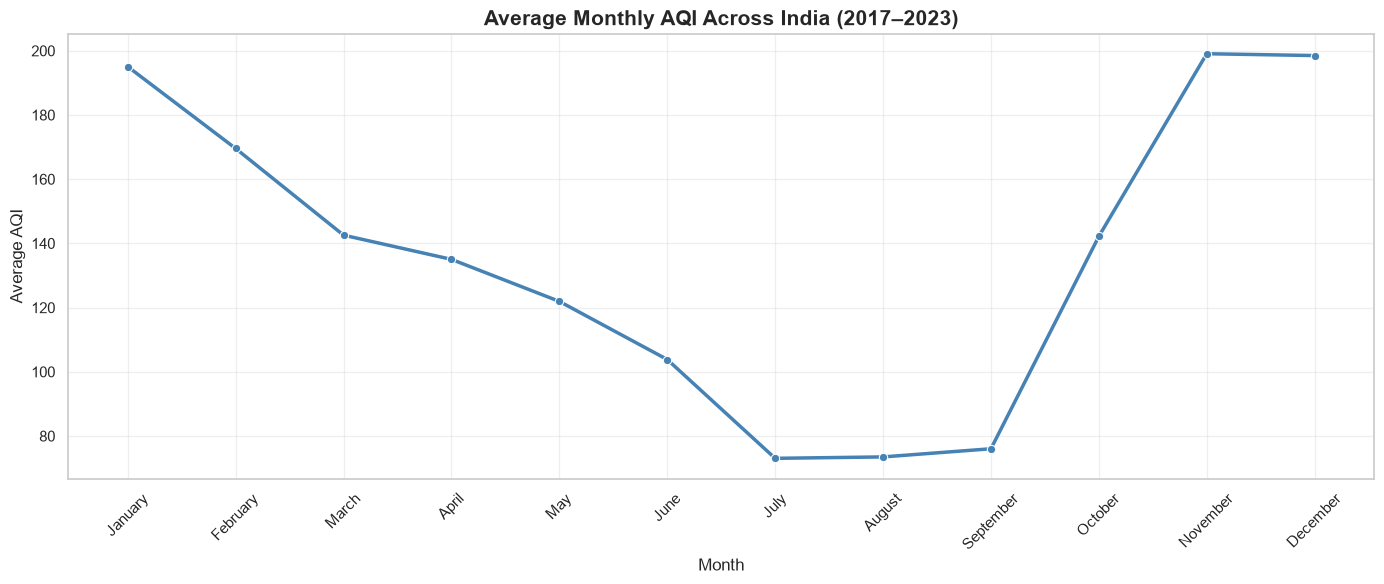

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_aqi,
    x="Month_Name",
    y="Average_AQI",
    marker="o",
    linewidth=2.5,
    color="steelblue"
)

plt.title(
    "Average Monthly AQI Across India (2017–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Average AQI", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
highest_month = monthly_aqi.loc[
    monthly_aqi["Average_AQI"].idxmax()
]

lowest_month = monthly_aqi.loc[
    monthly_aqi["Average_AQI"].idxmin()
]

print("Highest AQI Month:")
display(highest_month)

print("\nLowest AQI Month:")
display(lowest_month)

Highest AQI Month:


Month                       11
Average_AQI             199.07
Median_AQI               158.0
Valid_Observations     1145725
Month_Name            November
Name: 10, dtype: object


Lowest AQI Month:


Month                       7
Average_AQI             73.05
Median_AQI               59.0
Valid_Observations    1055011
Month_Name               July
Name: 6, dtype: object

### Key Insights

1. November recorded the highest average AQI at 199.07,
   followed by December (198.50) and January (195.05).

2. July recorded the lowest average AQI at 73.05,
   followed by August (73.49) and September (76.03).

3. AQI generally declined from January through July,
   indicating a broad reduction in recorded pollution levels.

4. A sharp increase occurred from September (76.03)
   to October (142.19), followed by elevated AQI
   throughout November and December.

5. The monthly pattern suggests a recurring seasonal
   variation in air quality across the dataset.

### Analytical Limitation

These values represent pooled monthly averages across
2017–2023 and all monitored locations. They do not
establish that every city or year follows the same pattern.
Changes in monitoring coverage may also influence the results.

## Year-wise Monthly AQI Analysis

This section compares monthly average AQI across individual
years from 2017 to 2023.

The objective is to identify recurring monthly patterns,
year-specific variations, and changes in seasonal pollution.

In [57]:
yearly_monthly_aqi = (
    df_analytical
    .dropna(subset=["AQI_Valid"])
    .groupby(["Year", "Month"])
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
)

yearly_monthly_aqi["Average_AQI"] = (
    yearly_monthly_aqi["Average_AQI"].round(2)
)

monthly_pivot = yearly_monthly_aqi.pivot(
    index="Month",
    columns="Year",
    values="Average_AQI"
)

monthly_pivot.index = monthly_pivot.index.map({
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
})

display(monthly_pivot)

Year,2017,2018,2019,2020,2021,2022,2023
Month,,,,,,,
January,238.10,233.94,231.73,184.14,202.84,174.06,187.81
February,211.36,204.33,176.33,168.54,183.89,156.02,157.83
March,155.67,177.24,150.36,108.76,159.60,160.55,123.42
April,163.74,163.94,161.29,90.17,137.61,156.40,121.60
May,161.50,161.22,165.97,100.61,95.57,134.61,109.38
June,122.06,140.18,131.91,84.13,92.94,113.30,92.21
July,82.40,86.90,94.81,65.35,74.33,67.25,67.09
August,37.13,89.84,74.17,56.20,73.99,69.47,80.20
September,91.83,97.62,75.42,86.50,63.25,74.55,74.23


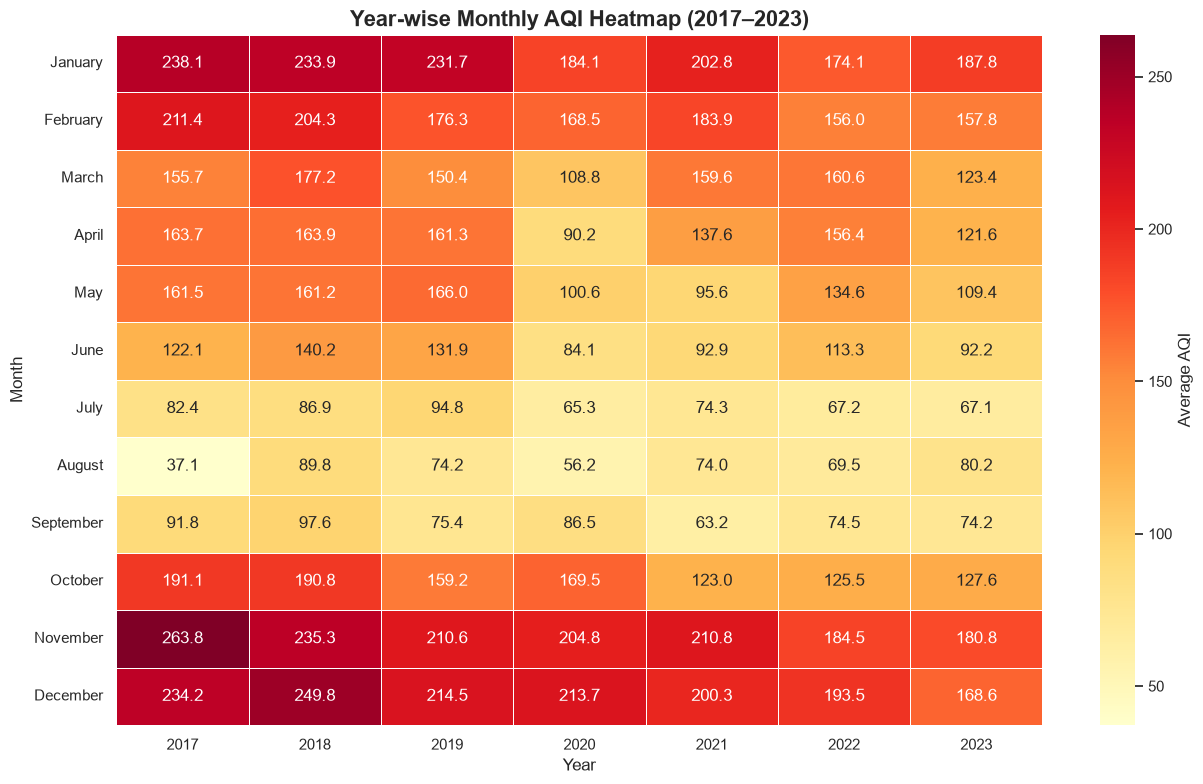

In [58]:
plt.figure(figsize=(13, 8))

sns.heatmap(
    monthly_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Average AQI"}
)

plt.title(
    "Year-wise Monthly AQI Heatmap (2017–2023)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Month", fontsize=12)

plt.tight_layout()
plt.show()

In [59]:
year_extremes = (
    yearly_monthly_aqi.loc[
        yearly_monthly_aqi.groupby("Year")["Average_AQI"].idxmax()
    ][["Year", "Month", "Average_AQI"]]
    .rename(columns={
        "Month": "Highest_AQI_Month",
        "Average_AQI": "Highest_AQI"
    })
)

lowest_months = (
    yearly_monthly_aqi.loc[
        yearly_monthly_aqi.groupby("Year")["Average_AQI"].idxmin()
    ][["Year", "Month", "Average_AQI"]]
    .rename(columns={
        "Month": "Lowest_AQI_Month",
        "Average_AQI": "Lowest_AQI"
    })
)

year_extremes = year_extremes.merge(
    lowest_months,
    on="Year"
)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

year_extremes["Highest_AQI_Month"] = (
    year_extremes["Highest_AQI_Month"].map(month_names)
)

year_extremes["Lowest_AQI_Month"] = (
    year_extremes["Lowest_AQI_Month"].map(month_names)
)

display(year_extremes.round(2))

,Year,Highest_AQI_Month,Highest_AQI,Lowest_AQI_Month,Lowest_AQI
0,2017,November,263.83,August,37.13
1,2018,December,249.81,July,86.90
2,2019,January,231.73,August,74.17
3,2020,December,213.65,August,56.20
4,2021,November,210.83,September,63.25
5,2022,December,193.52,July,67.25
6,2023,January,187.81,July,67.09


### Key Insights

1. November and December frequently recorded the highest
   monthly AQI values across the seven-year period.

2. January was the highest-AQI month in 2019 and 2023,
   demonstrating that the peak pollution month varies by year.

3. July and August were generally among the lowest-AQI months.
   September recorded the lowest value in 2021.

4. The heatmap reveals a recurring seasonal pattern:
   elevated AQI during late autumn and winter and lower AQI
   during the monsoon period.

5. Several months recorded lower average AQI in 2023 than
   in 2017, although this comparison does not establish
   the reasons behind the changes.

### Analytical Limitation

The analysis uses pooled observations from available monitoring
stations in each year. Changes in station coverage and data
availability may influence the comparisons.

## Seasonal AQI Analysis

This section compares average and median AQI across four seasons.

The objective is to identify seasonal pollution patterns and
understand how air quality varies across different periods
of the year.

In [60]:
seasonal_aqi = (
    df_analytical
    .dropna(subset=["AQI_Valid"])
    .groupby("Season")
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Minimum_AQI=("AQI_Valid", "min"),
        Maximum_AQI=("AQI_Valid", "max"),
        Valid_Observations=("AQI_Valid", "count"),
        Cities=("City", "nunique"),
        Stations=("Station", "nunique")
    )
    .reset_index()
)

seasonal_aqi["Average_AQI"] = seasonal_aqi["Average_AQI"].round(2)

seasonal_aqi["Median_AQI"] = seasonal_aqi["Median_AQI"].round(2)

display(seasonal_aqi)

,Season,Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Valid_Observations,Cities,Stations
0,Monsoon,81.25,65.0,1.0,500.0,4173626,238,509
1,Post-Monsoon,170.70,127.0,1.0,500.0,2286273,244,522
2,Summer,133.22,106.0,1.0,500.0,2933894,220,465
3,Winter,188.96,149.0,1.0,500.0,3079692,248,528


### Key Insights

1. Winter recorded the highest average AQI (188.96),
   followed by Post-Monsoon (170.70).

2. Monsoon recorded the lowest average AQI (81.25),
   indicating substantially lower recorded pollution levels.

3. Summer recorded an average AQI of 133.22,
   placing it between Monsoon and Post-Monsoon.

4. The difference between Winter and Monsoon average
   AQI was 107.71 points.

5. The results indicate a strong seasonal pattern,
   with higher AQI during Winter and Post-Monsoon
   and lower AQI during Monsoon.

### Analytical Limitation

The number of monitored stations and cities differs
between seasons. Consequently, seasonal averages may
be influenced by differences in monitoring coverage.

AQI readings above 500 were excluded from these
calculations and retained separately in the original
dataset for data-quality auditing.

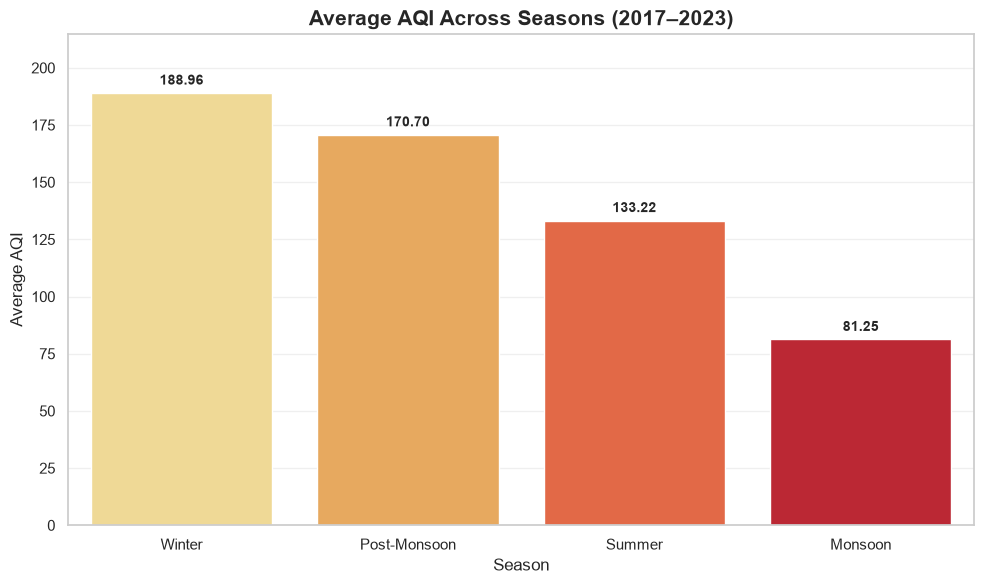

In [70]:
# Plot average AQI across seasons

season_order = [
    "Winter",
    "Post-Monsoon",
    "Summer",
    "Monsoon"
]

seasonal_plot = seasonal_aqi.copy()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=seasonal_plot,
    x="Season",
    y="Average_AQI",
    order=season_order,
    hue="Season",
    hue_order=season_order,
    palette="YlOrRd",
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Average AQI Across Seasons (2017–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.grid(axis="y", alpha=0.3)
plt.ylim(0, 215)

plt.tight_layout()
plt.show()

In [ ]:
seasonal_category_counts = (
    df_analytical
    .dropna(subset=["AQI_Valid", "AQI_Category"])
    .groupby(["Season", "AQI_Category"])
    .size()
    .reset_index(name="Observation_Count")
)

seasonal_category_counts["Season_Total"] = (
    seasonal_category_counts
    .groupby("Season")["Observation_Count"]
    .transform("sum")
)

seasonal_category_counts["Percentage"] = (
    seasonal_category_counts["Observation_Count"]
    / seasonal_category_counts["Season_Total"]
) * 100

seasonal_category_counts["Percentage"] = (
    seasonal_category_counts["Percentage"].round(2)
)

display(
    seasonal_category_counts.sort_values(
        ["Season", "Percentage"],
        ascending=[True, False]
    )
)

,Season,AQI_Category,Observation_Count,Season_Total,Percentage
3,Monsoon,Satisfactory,1693496,4173626,40.58
0,Monsoon,Good,1431185,4173626,34.29
1,Monsoon,Moderate,868160,4173626,20.80
2,Monsoon,Poor,108891,4173626,2.61
5,Monsoon,Very Poor,44298,4173626,1.06
4,Monsoon,Severe,27596,4173626,0.66
7,Post-Monsoon,Moderate,719516,2286273,31.47
9,Post-Monsoon,Satisfactory,566889,2286273,24.80
11,Post-Monsoon,Very Poor,315027,2286273,13.78
6,Post-Monsoon,Good,281424,2286273,12.31


In [ ]:
category_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

season_order = [
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
]

seasonal_category_pivot = (
    seasonal_category_counts
    .pivot(
        index="Season",
        columns="AQI_Category",
        values="Percentage"
    )
    .reindex(index=season_order, columns=category_order)
    .fillna(0)
)

display(seasonal_category_pivot.round(2))

AQI_Category,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
Season,,,,,,
Winter,6.62,23.17,32.43,12.90,18.24,6.64
Summer,12.34,33.55,36.49,9.08,6.32,2.22
Monsoon,34.29,40.58,20.80,2.61,1.06,0.66
Post-Monsoon,12.31,24.80,31.47,10.97,13.78,6.68


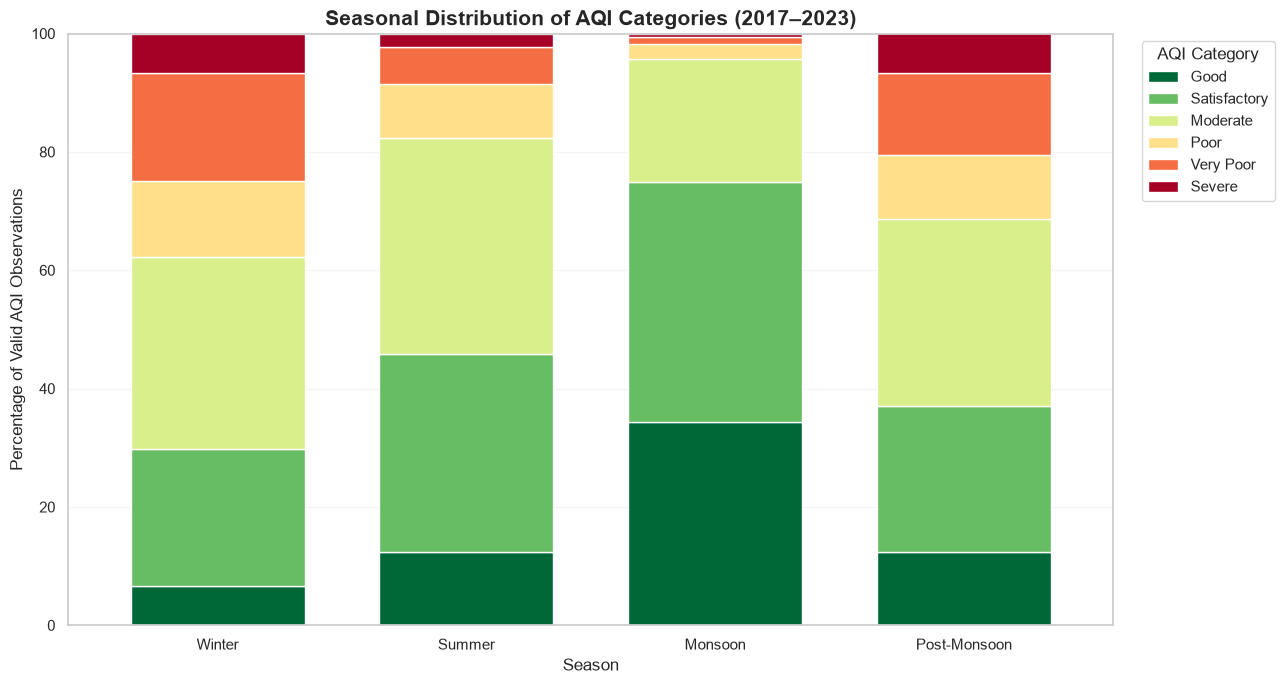

In [ ]:
ax = seasonal_category_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    colormap="RdYlGn_r",
    width=0.7
)

plt.title(
    "Seasonal Distribution of AQI Categories (2017–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Season")
plt.ylabel("Percentage of Valid AQI Observations")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(
    title="AQI Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
print("AQI category counts:")
print(df_analytical["AQI_Category"].value_counts(dropna=False))

print("\nValid AQI readings:")
print(df_analytical["AQI_Valid"].notna().sum())

print("\nValid AQI readings with missing category:")
print(
    df_analytical.loc[
        df_analytical["AQI_Valid"].notna(),
        "AQI_Category"
    ].isna().sum()
)

print("\nValid AQI readings with Unclassified category:")
print(
    (
        df_analytical["AQI_Valid"].notna()
        & df_analytical["AQI_Category"].eq("Unclassified")
    ).sum()
)

AQI category counts:
AQI_Category
Satisfactory    3958356
Moderate        3656970
Good            2278540
Very Poor       1106391
Unclassified    1035587
Poor            1023263
Severe           449965
Name: count, dtype: int64

Valid AQI readings:
12473485

Valid AQI readings with missing category:
0

Valid AQI readings with Unclassified category:
0


### Key Insights

1. Winter has the highest proportion of observations in the
   Poor, Very Poor and Severe categories, collectively
   accounting for 37.78%.

2. Post-Monsoon follows with 31.43% of observations in
   these three higher-pollution categories.

3. Monsoon has the most favourable distribution, with
   74.87% of observations classified as Good or Satisfactory.

4. Summer shows an intermediate pattern, with 45.89%
   Good or Satisfactory observations and 17.62% in
   Poor, Very Poor or Severe categories.

5. The results indicate that pollution severity varies
   considerably across seasons.

### Data Validation

The six valid AQI categories account for all 12,473,485
valid observations. No valid observation has a missing
or Unclassified category.

The 1,035,587 Unclassified records in the original
dataset correspond exactly to 1,035,531 missing readings
and 56 out-of-range readings.

These records were excluded from seasonal category
percentages.

## City-wise Seasonal Pollution Analysis

This section examines how AQI varies across seasons
within individual cities.

The objective is to identify cities with elevated
seasonal pollution levels and understand regional
differences in pollution patterns.

In [ ]:
city_seasonal_aqi = (
    df_analytical
    .dropna(subset=["AQI_Valid"])
    .groupby(["State", "City", "Season"])
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
)

city_seasonal_aqi["Average_AQI"] = (
    city_seasonal_aqi["Average_AQI"].round(2)
)

print("City-season records:", city_seasonal_aqi.shape)

display(city_seasonal_aqi.head(10))

City-season records: (950, 6)


,State,City,Season,Average_AQI,Median_AQI,Valid_Observations
0,Andhra Pradesh,Amaravati,Monsoon,45.69,39.0,15368
1,Andhra Pradesh,Amaravati,Post-Monsoon,85.56,78.0,7899
2,Andhra Pradesh,Amaravati,Summer,63.99,60.0,12192
3,Andhra Pradesh,Amaravati,Winter,125.50,103.0,12942
4,Andhra Pradesh,Anantapur,Monsoon,58.53,54.0,3375
5,Andhra Pradesh,Anantapur,Post-Monsoon,77.14,70.0,2388
6,Andhra Pradesh,Anantapur,Summer,58.89,53.0,2082
7,Andhra Pradesh,Anantapur,Winter,73.77,68.0,2791
8,Andhra Pradesh,Chittoor,Monsoon,45.04,42.0,2803
9,Andhra Pradesh,Chittoor,Post-Monsoon,96.73,81.0,1578


In [ ]:
MIN_SEASON_OBSERVATIONS = 3000

city_seasonal_filtered = city_seasonal_aqi[
    city_seasonal_aqi["Valid_Observations"] >= MIN_SEASON_OBSERVATIONS
].copy()

print("Original city-season records:", len(city_seasonal_aqi))
print("Filtered city-season records:", len(city_seasonal_filtered))

print(
    "Unique cities after filtering:",
    city_seasonal_filtered[["State", "City"]]
    .drop_duplicates()
    .shape[0]
)

display(city_seasonal_filtered.head(10))

Original city-season records: 950
Filtered city-season records: 625
Unique cities after filtering: 169


,State,City,Season,Average_AQI,Median_AQI,Valid_Observations
0,Andhra Pradesh,Amaravati,Monsoon,45.69,39.0,15368
1,Andhra Pradesh,Amaravati,Post-Monsoon,85.56,78.0,7899
2,Andhra Pradesh,Amaravati,Summer,63.99,60.0,12192
3,Andhra Pradesh,Amaravati,Winter,125.50,103.0,12942
4,Andhra Pradesh,Anantapur,Monsoon,58.53,54.0,3375
16,Andhra Pradesh,Rajamahendravaram,Monsoon,51.23,46.0,17132
17,Andhra Pradesh,Rajamahendravaram,Post-Monsoon,92.11,84.0,8829
18,Andhra Pradesh,Rajamahendravaram,Summer,69.03,61.0,12552
19,Andhra Pradesh,Rajamahendravaram,Winter,138.25,121.0,12948
24,Andhra Pradesh,Vijayawada,Monsoon,54.15,48.0,9027


In [ ]:
season_order = [
    "Winter",
    "Post-Monsoon",
    "Summer",
    "Monsoon"
]

top_cities_by_season = (
    city_seasonal_filtered
    .sort_values(
        ["Season", "Average_AQI"],
        ascending=[True, False]
    )
    .groupby("Season")
    .head(10)
    .sort_values(
        ["Season", "Average_AQI"],
        ascending=[True, False]
    )
)

display(
    top_cities_by_season[
        [
            "State",
            "City",
            "Season",
            "Average_AQI",
            "Median_AQI",
            "Valid_Observations"
        ]
    ]
)

,State,City,Season,Average_AQI,Median_AQI,Valid_Observations
192,Gujarat,Nandesari,Monsoon,147.42,112.0,5123
694,Rajasthan,Bhiwadi,Monsoon,144.23,119.0,16221
869,Uttar Pradesh,Ghaziabad,Monsoon,126.90,107.0,45279
288,Haryana,Sonipat,Monsoon,125.19,106.0,11594
905,Uttar Pradesh,Noida,Monsoon,120.61,102.0,87900
236,Haryana,Gurugram,Monsoon,117.34,92.0,46161
176,Delhi,Delhi,Monsoon,116.76,101.0,575994
124,Bihar,Saharsa,Monsoon,116.32,84.0,4755
212,Haryana,Ballabgarh,Monsoon,115.49,100.0,13819
108,Bihar,Munger,Monsoon,114.24,103.0,4991


In [ ]:
# Identify cities having sufficient observations in all four seasons

EXPECTED_SEASONS = {
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
}

city_season_coverage = (
    city_seasonal_filtered
    .groupby(["State", "City"])
    .agg(
        Seasons_Available=("Season", "nunique"),
        Total_Observations=("Valid_Observations", "sum"),
        Minimum_Seasonal_Observations=("Valid_Observations", "min")
    )
    .reset_index()
)

balanced_cities = city_season_coverage[
    city_season_coverage["Seasons_Available"] == 4
][["State", "City"]]

balanced_city_seasonal = city_seasonal_filtered.merge(
    balanced_cities,
    on=["State", "City"],
    how="inner"
)

print("Cities with all four seasons:", len(balanced_cities))
print("Balanced city-season records:", len(balanced_city_seasonal))

display(
    balanced_city_seasonal.sort_values(
        ["State", "City", "Season"]
    ).head(20)
)

Cities with all four seasons: 142
Balanced city-season records: 568


,State,City,Season,Average_AQI,Median_AQI,Valid_Observations
0,Andhra Pradesh,Amaravati,Monsoon,45.69,39.0,15368
1,Andhra Pradesh,Amaravati,Post-Monsoon,85.56,78.0,7899
2,Andhra Pradesh,Amaravati,Summer,63.99,60.0,12192
3,Andhra Pradesh,Amaravati,Winter,125.50,103.0,12942
4,Andhra Pradesh,Rajamahendravaram,Monsoon,51.23,46.0,17132
5,Andhra Pradesh,Rajamahendravaram,Post-Monsoon,92.11,84.0,8829
6,Andhra Pradesh,Rajamahendravaram,Summer,69.03,61.0,12552
7,Andhra Pradesh,Rajamahendravaram,Winter,138.25,121.0,12948
8,Andhra Pradesh,Vijayawada,Monsoon,54.15,48.0,9027
9,Andhra Pradesh,Vijayawada,Post-Monsoon,81.60,71.0,6935


### Seasonal AQI Comparison Across Cities

This analysis compares seasonal average AQI across cities with
sufficient observations in all four seasons.

The heatmap highlights geographical differences in seasonal
pollution patterns and identifies cities with consistently
high or seasonally concentrated pollution.

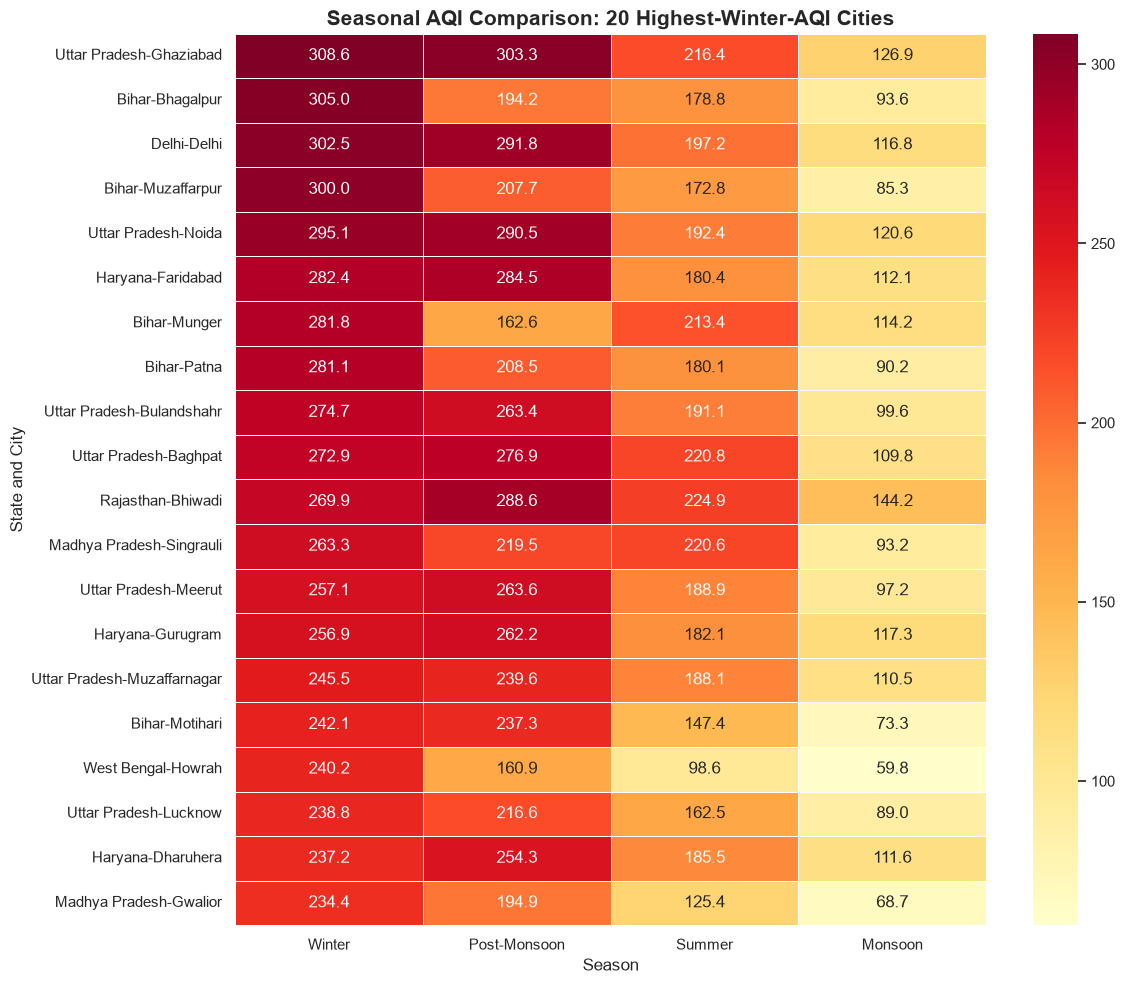

In [ ]:
# Arrange seasonal AQI values into columns
city_season_pivot = balanced_city_seasonal.pivot(
    index=["State", "City"],
    columns="Season",
    values="Average_AQI"
)

# Select the 20 cities with the highest Winter AQI
top_winter_cities = (
    city_season_pivot
    .sort_values("Winter", ascending=False)
    .head(20)
)

# Display Winter AQI first, followed by other seasons
season_columns = [
    "Winter",
    "Post-Monsoon",
    "Summer",
    "Monsoon"
]

top_winter_cities = top_winter_cities[season_columns]

plt.figure(figsize=(12, 10))

sns.heatmap(
    top_winter_cities,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title(
    "Seasonal AQI Comparison: 20 Highest-Winter-AQI Cities",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Season")
plt.ylabel("State and City")
plt.tight_layout()
plt.show()

In [ ]:
city_season_variation = (
    city_season_pivot
    .copy()
    .reset_index()
)

city_season_variation["Highest_Season_AQI"] = (
    city_season_variation[season_columns].max(axis=1)
)

city_season_variation["Lowest_Season_AQI"] = (
    city_season_variation[season_columns].min(axis=1)
)

city_season_variation["Seasonal_AQI_Range"] = (
    city_season_variation["Highest_Season_AQI"]
    - city_season_variation["Lowest_Season_AQI"]
)

city_season_variation["Highest_AQI_Season"] = (
    city_season_variation[season_columns].idxmax(axis=1)
)

city_season_variation["Lowest_AQI_Season"] = (
    city_season_variation[season_columns].idxmin(axis=1)
)

city_season_variation = city_season_variation.sort_values(
    "Seasonal_AQI_Range",
    ascending=False
)

display(city_season_variation.head(15).round(2))

Season,State,City,Monsoon,Post-Monsoon,Summer,Winter,Highest_Season_AQI,Lowest_Season_AQI,Seasonal_AQI_Range,Highest_AQI_Season,Lowest_AQI_Season
10,Bihar,Muzaffarpur,85.34,207.70,172.80,299.98,299.98,85.34,214.64,Winter,Monsoon
5,Bihar,Bhagalpur,93.62,194.20,178.75,304.98,304.98,93.62,211.36,Winter,Monsoon
11,Bihar,Patna,90.23,208.54,180.13,281.08,281.08,90.23,190.85,Winter,Monsoon
17,Delhi,Delhi,116.76,291.76,197.20,302.46,302.46,116.76,185.70,Winter,Monsoon
126,Uttar Pradesh,Ghaziabad,126.90,303.30,216.36,308.58,308.58,126.90,181.68,Winter,Monsoon
139,West Bengal,Howrah,59.77,160.94,98.61,240.15,240.15,59.77,180.38,Winter,Monsoon
124,Uttar Pradesh,Bulandshahr,99.59,263.45,191.13,274.66,274.66,99.59,175.07,Winter,Monsoon
134,Uttar Pradesh,Noida,120.61,290.47,192.41,295.11,295.11,120.61,174.50,Winter,Monsoon
29,Haryana,Faridabad,112.13,284.54,180.40,282.35,284.54,112.13,172.41,Post-Monsoon,Monsoon
84,Madhya Pradesh,Singrauli,93.21,219.54,220.63,263.30,263.30,93.21,170.09,Winter,Monsoon


### Key Findings: Seasonal AQI Differences Across Cities

1. Northern Indian cities such as Ghaziabad, Delhi, Noida,
   Bhagalpur and Muzaffarpur show high Winter AQI values.

2. Ghaziabad recorded the highest Winter average AQI among
   the 142 balanced cities, at approximately 308.58.

3. Winter and Post-Monsoon pollution levels are particularly
   elevated in several cities across Bihar, Uttar Pradesh,
   Haryana and Delhi.

4. Monsoon generally records substantially lower AQI values
   among the cities examined.

5. Muzaffarpur recorded the highest seasonal AQI range
   (214.64), followed by Bhagalpur (211.36) and Patna (190.85).

6. Seasonal pollution patterns differ by city. Some locations,
   including Faridabad and Baghpat, recorded higher
   Post-Monsoon averages than Winter averages.

Note: These results are descriptive averages pooled across
2017–2023. They do not establish causal relationships.

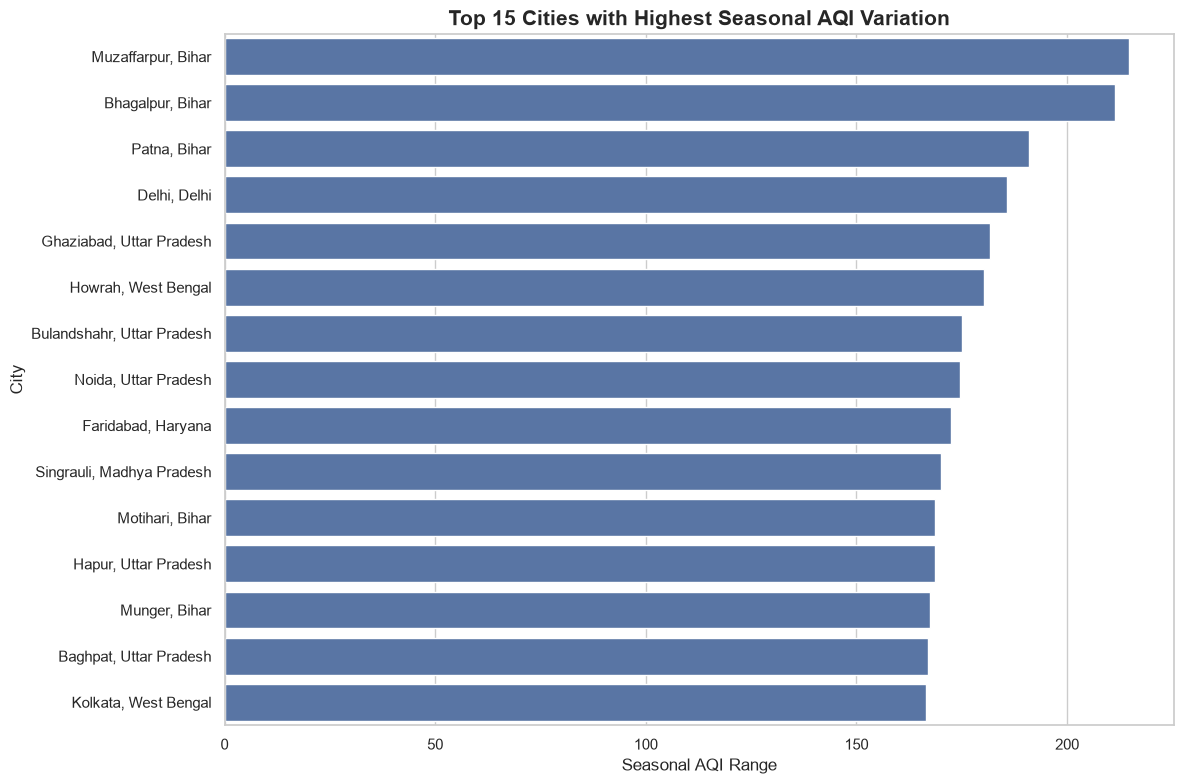

In [ ]:
top_seasonal_variation = city_season_variation.head(15).copy()

top_seasonal_variation["City_Label"] = (
    top_seasonal_variation["City"]
    + ", "
    + top_seasonal_variation["State"]
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_seasonal_variation,
    x="Seasonal_AQI_Range",
    y="City_Label"
)

plt.title(
    "Top 15 Cities with Highest Seasonal AQI Variation",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Seasonal AQI Range")
plt.ylabel("City")

plt.tight_layout()
plt.show()

### Key Findings — Seasonal AQI Analysis (2017–2023)

The seasonal analysis reveals substantial variation in air quality across India.

**1. Seasonal pollution patterns**
- Winter recorded the highest average AQI of 188.96, followed by Post-Monsoon (170.70), Summer (133.22) and Monsoon (81.25).
- Monsoon had the most favourable AQI distribution, with approximately 74.87% of observations classified as Good or Satisfactory.
- Winter recorded the highest combined proportion of Very Poor and Severe observations (24.88%).

**2. Regional differences**
- Several cities in Bihar, Uttar Pradesh, Delhi and Haryana exhibited high winter and post-monsoon AQI values.
- Muzaffarpur, Bhagalpur, Patna, Delhi and Ghaziabad were among the cities with the largest seasonal AQI variation.
- Monsoon AQI was substantially lower than winter AQI in many of these cities.

**3. Balanced city comparison**
- The analysis retained 142 cities with observations across all four seasons, producing 568 city-season records.
- This improves comparability by avoiding comparisons involving cities with missing seasonal coverage.

**4. Analytical limitation**

These findings describe patterns in the available monitoring data. They do not establish causal relationships between seasons, weather conditions and pollution levels. Differences in monitoring coverage and observation counts should also be considered when interpreting city-level rankings.

## Year-wise Seasonal AQI Trends (2017–2023)

This section investigates how seasonal AQI patterns changed
across individual years.

The objective is to determine whether winter consistently
records higher AQI levels and whether seasonal pollution
patterns have changed over the study period.

In [ ]:
df_analytical["Year"] = df_analytical["Timestamp"].dt.year

yearly_seasonal_aqi = (
    df_analytical
    .dropna(subset=["AQI_Valid", "Season"])
    .groupby(["Year", "Season"])
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count"),
        Cities=("City", "nunique"),
        Stations=("Station", "nunique")
    )
    .reset_index()
)

yearly_seasonal_aqi["Average_AQI"] = (
    yearly_seasonal_aqi["Average_AQI"].round(2)
)

display(yearly_seasonal_aqi)

,Year,Season,Average_AQI,Median_AQI,Valid_Observations,Cities,Stations
0,2017,Monsoon,93.49,70.0,55058,32,60
1,2017,Post-Monsoon,220.54,187.0,58385,42,75
2,2017,Summer,160.30,118.0,50177,21,34
3,2017,Winter,231.05,203.0,76461,48,82
4,2018,Monsoon,102.05,80.0,303503,65,126
5,2018,Post-Monsoon,213.09,173.0,167885,66,130
6,2018,Summer,167.91,136.0,196045,60,111
7,2018,Winter,231.66,196.0,209741,69,134
8,2019,Monsoon,93.20,74.0,467592,102,196
9,2019,Post-Monsoon,184.40,139.0,260573,101,196


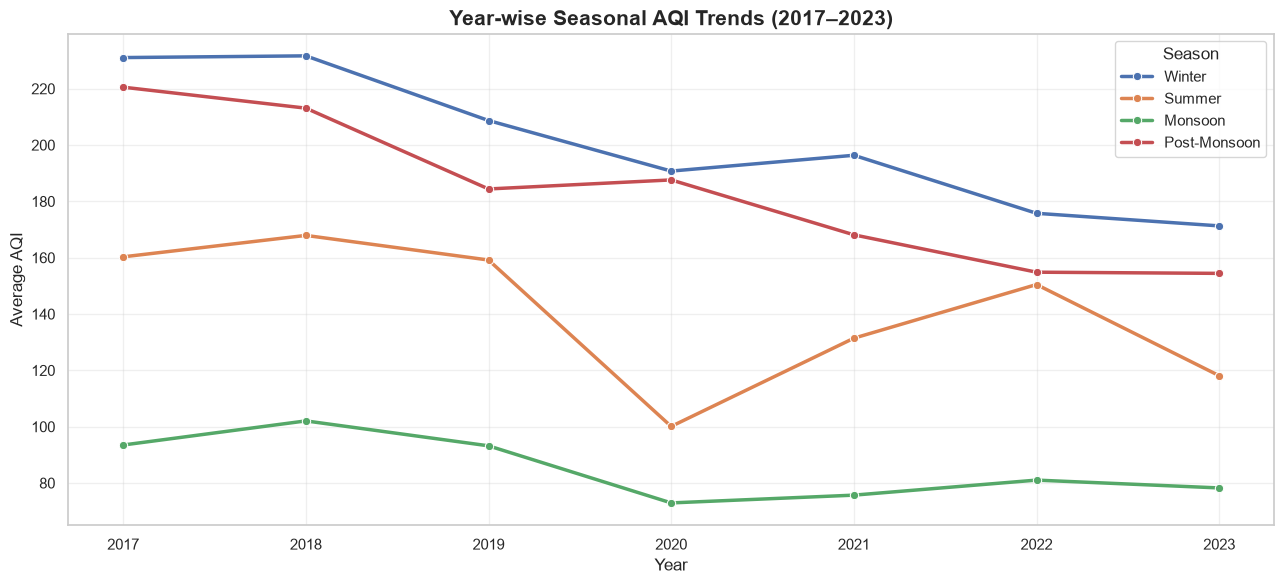

In [ ]:
season_order = [
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
]

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=yearly_seasonal_aqi,
    x="Year",
    y="Average_AQI",
    hue="Season",
    hue_order=season_order,
    marker="o",
    linewidth=2.5
)

plt.title(
    "Year-wise Seasonal AQI Trends (2017–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.xticks(range(2017, 2024))
plt.grid(alpha=0.3)
plt.legend(title="Season")
plt.tight_layout()
plt.show()

### Key Findings — Year-wise Seasonal AQI Trends (2017–2023)

The year-wise analysis confirms a consistent seasonal pattern across the study period.

**1. Winter consistently records the highest AQI**

Winter had the highest average AQI in every year from 2017 to 2023. Its average declined from 231.05 in 2017 to 171.29 in 2023.

**2. Monsoon consistently records the lowest AQI**

Monsoon had the lowest average AQI in all seven years, with annual averages ranging from 72.93 to 102.05.

**3. Post-Monsoon remains a high-pollution period**

Post-Monsoon was generally the second-most polluted season, with its average AQI declining from 220.54 in 2017 to 154.43 in 2023.

**4. Summer shows greater fluctuations**

Summer AQI dropped considerably in 2020, followed by a recovery in 2021 and 2022. This pattern warrants further investigation but does not independently establish a cause.

**5. Monitoring coverage limitation**

The monitoring network expanded substantially during the study period. For example, the number of stations contributing to winter observations increased from 82 in 2017 to 518 in 2023.

Consequently, changes in annual seasonal averages may reflect both actual air-quality variation and changes in monitoring coverage. These results should be interpreted as descriptive trends rather than definitive evidence of nationwide pollution improvement.

## Balanced City-Year-Season Analysis

This section creates a consistent comparison group of cities
with sufficient AQI observations across all four seasons
and all seven years.

The objective is to reduce the influence of changing city
coverage when examining long-term seasonal AQI patterns.

In [62]:
# Create year and season columns
df_analytical["Year"] = df_analytical["Timestamp"].dt.year

# Count valid observations for each city, year and season
city_year_season_coverage = (
    df_analytical
    .dropna(subset=["AQI_Valid", "Season"])
    .groupby(["State", "City", "Year", "Season"])
    .agg(
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
)

display(city_year_season_coverage.head())
print("City-year-season records:", len(city_year_season_coverage))

,State,City,Year,Season,Valid_Observations
0,Andhra Pradesh,Amaravati,2017,Winter,489
1,Andhra Pradesh,Amaravati,2018,Monsoon,2599
2,Andhra Pradesh,Amaravati,2018,Post-Monsoon,999
3,Andhra Pradesh,Amaravati,2018,Summer,1690
4,Andhra Pradesh,Amaravati,2018,Winter,2051


City-year-season records: 3468


In [63]:
# Count how many year-season combinations each city has
city_coverage_summary = (
    city_year_season_coverage
    .groupby(["State", "City"])
    .agg(
        Available_Combinations=("Season", "count"),
        Minimum_Observations=("Valid_Observations", "min"),
        Median_Observations=("Valid_Observations", "median"),
        Total_Observations=("Valid_Observations", "sum")
    )
    .reset_index()
)

print("Total unique cities:", len(city_coverage_summary))

print("\nAvailable year-season combinations:")
display(
    city_coverage_summary["Available_Combinations"]
    .value_counts()
    .sort_index()
)

print("\nObservation count distribution:")
display(
    city_coverage_summary[
        ["Minimum_Observations", "Median_Observations", "Total_Observations"]
    ].describe().round(2)
)

Total unique cities: 248

Available year-season combinations:


Available_Combinations
1      3
2      8
3     17
4     31
5      5
6     16
7     10
8      7
9      3
10    10
11     8
12     9
13     2
14     5
16    12
17     2
18     1
19    10
20    21
21     3
22     2
23     4
24    11
25     7
26    11
27    10
28    20
Name: count, dtype: int64


Observation count distribution:


,Minimum_Observations,Median_Observations,Total_Observations
count,248.00,248.00,248.00
mean,687.19,2621.80,50296.31
std,1030.80,5172.03,139535.96
min,1.00,147.00,187.00
25%,255.25,1455.88,7747.00
50%,636.00,1888.50,24540.00
75%,785.75,2079.50,43970.75
max,14841.00,70404.50,1777818.00


In [64]:
# Identify cities with complete year-season coverage

EXPECTED_COMBINATIONS = 7 * 4  # 2017–2023, four seasons

complete_coverage_cities = city_coverage_summary[
    city_coverage_summary["Available_Combinations"] == EXPECTED_COMBINATIONS
].copy()

print("Cities with all 28 year-season combinations:",
      len(complete_coverage_cities))

print("\nCoverage distribution:")
display(
    city_coverage_summary["Available_Combinations"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Cities")
)

print("\nCities with complete coverage:")
display(
    complete_coverage_cities.sort_values(
        "Total_Observations", ascending=False
    ).head(15)
)

Cities with all 28 year-season combinations: 20

Coverage distribution:


,Number_of_Cities
Available_Combinations,
1,3
2,8
3,17
4,31
5,5
6,16
7,10
8,7
9,3



Cities with complete coverage:


,State,City,Available_Combinations,Minimum_Observations,Median_Observations,Total_Observations
44,Delhi,Delhi,28,14841,70404.5,1777818
140,Maharashtra,Mumbai,28,1136,28592.5,752868
80,Karnataka,Bengaluru,28,4128,18559.0,465038
220,Telangana,Hyderabad,28,3887,12247.5,390518
236,Uttar Pradesh,Noida,28,658,8476.5,254860
29,Bihar,Patna,28,812,8436.0,208209
59,Haryana,Gurugram,28,1058,5242.5,144826
245,West Bengal,Howrah,28,694,4987.0,133889
227,Uttar Pradesh,Ghaziabad,28,671,5001.0,132892
57,Haryana,Faridabad,28,1012,4991.0,131396


In [65]:
# Evaluate minimum observation thresholds
# Only consider cities with all 28 year-season combinations

thresholds = [500, 1000, 2000]

threshold_results = []

for threshold in thresholds:

    eligible_cities = complete_coverage_cities[
        complete_coverage_cities["Minimum_Observations"] >= threshold
    ]

    threshold_results.append({
        "Minimum_Observations_Required": threshold,
        "Eligible_Cities": len(eligible_cities),
        "Total_Cities": len(complete_coverage_cities)
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison)

,Minimum_Observations_Required,Eligible_Cities,Total_Cities
0,500,17,20
1,1000,8,20
2,2000,3,20


### Balanced City-Year-Season Comparison

To ensure consistent comparisons across time, cities were required to
have all 28 year-season combinations (7 years × 4 seasons) between
2017 and 2023.

A minimum threshold of 500 valid AQI observations was applied to
every city-year-season combination.

This filtering process retained 17 cities with complete temporal
coverage and sufficient observations in every combination.

The resulting dataset supports a more consistent comparison of
seasonal AQI patterns across cities and years.

In [72]:
# Create city-year-season AQI summary

city_year_season = (
    df_analytical
    .dropna(subset=["AQI_Valid", "Season"])
    .groupby(["State", "City", "Year", "Season"])
    .agg(
        Average_AQI=("AQI_Valid", "mean"),
        Median_AQI=("AQI_Valid", "median"),
        Valid_Observations=("AQI_Valid", "count")
    )
    .reset_index()
)

city_year_season[["Average_AQI", "Median_AQI"]] = (
    city_year_season[["Average_AQI", "Median_AQI"]].round(2)
)

print("City-year-season summary:", city_year_season.shape)


# Select cities meeting the minimum threshold

MIN_OBSERVATIONS = 500

eligible_cities_500 = complete_coverage_cities[
    complete_coverage_cities["Minimum_Observations"] >= MIN_OBSERVATIONS
][["State", "City"]].copy()

#Create balanced dataset

balanced_city_season_year = city_year_season.merge(
    eligible_cities_500,
    on=["State", "City"],
    how="inner"
)

balanced_city_season_year = (
    balanced_city_season_year
    .sort_values(["State", "City", "Year", "Season"])
    .reset_index(drop=True)
)

print("\nEligible cities:", len(eligible_cities_500))
print("Balanced dataset shape:", balanced_city_season_year.shape)

display(balanced_city_season_year.head(20))

City-year-season summary: (3468, 7)

Eligible cities: 17
Balanced dataset shape: (476, 7)


,State,City,Year,Season,Average_AQI,Median_AQI,Valid_Observations
0,Andhra Pradesh,Visakhapatnam,2017,Monsoon,90.72,85.0,1417
1,Andhra Pradesh,Visakhapatnam,2017,Post-Monsoon,94.71,89.0,1107
2,Andhra Pradesh,Visakhapatnam,2017,Summer,99.17,94.0,1846
3,Andhra Pradesh,Visakhapatnam,2017,Winter,156.64,138.0,2060
4,Andhra Pradesh,Visakhapatnam,2018,Monsoon,98.49,93.0,2407
5,Andhra Pradesh,Visakhapatnam,2018,Post-Monsoon,132.11,115.0,1199
6,Andhra Pradesh,Visakhapatnam,2018,Summer,89.37,83.0,2030
7,Andhra Pradesh,Visakhapatnam,2018,Winter,179.45,162.0,1844
8,Andhra Pradesh,Visakhapatnam,2019,Monsoon,91.38,87.0,2368
9,Andhra Pradesh,Visakhapatnam,2019,Post-Monsoon,119.01,99.0,1181


In [73]:
# Validate the balanced city-year-season dataset

expected_records = len(eligible_cities_500) * 28

print("Expected records:", expected_records)
print("Actual records:", len(balanced_city_season_year))

print(
    "Minimum observations:",
    balanced_city_season_year["Valid_Observations"].min()
)

print(
    "Maximum observations:",
    balanced_city_season_year["Valid_Observations"].max()
)

print(
    "Number of unique cities:",
    balanced_city_season_year[["State", "City"]].drop_duplicates().shape[0]
)

print(
    "Year range:",
    balanced_city_season_year["Year"].min(),
    "to",
    balanced_city_season_year["Year"].max()
)

assert len(balanced_city_season_year) == expected_records
assert balanced_city_season_year["Valid_Observations"].min() >= 500

assert (
    balanced_city_season_year
    .groupby(["State", "City"])
    .size()
    .eq(28)
    .all()
)

print("\nAll validation checks passed!")

Expected records: 476
Actual records: 476
Minimum observations: 623
Maximum observations: 99290
Number of unique cities: 17
Year range: 2017 to 2023

All validation checks passed!


In [74]:
# Calculate average AQI for each season across eligible cities
balanced_season_summary = (
    balanced_city_season_year
    .groupby("Season")
    .agg(
        Average_AQI=("Average_AQI", "mean"),
        Median_AQI=("Average_AQI", "median"),
        Number_of_Cities=("City", "nunique")
    )
    .reset_index()
)

balanced_season_summary[
    ["Average_AQI", "Median_AQI"]
] = balanced_season_summary[
    ["Average_AQI", "Median_AQI"]
].round(2)

balanced_season_summary

,Season,Average_AQI,Median_AQI,Number_of_Cities
0,Monsoon,94.66,92.46,17
1,Post-Monsoon,197.23,184.91,17
2,Summer,146.96,132.69,17
3,Winter,215.73,200.27,17


### Key Finding: Seasonal Pollution Patterns in Balanced Cities

The balanced analysis of 17 cities across 2017–2023 reveals a clear seasonal pattern in air pollution.

- Winter recorded the highest average AQI of **215.73**.
- Post-monsoon followed with an average AQI of **197.23**.
- Summer recorded an average AQI of **146.96**.
- Monsoon had the lowest average AQI of **94.66**.

The findings indicate substantially poorer air quality during winter and post-monsoon periods compared with the monsoon season. Since all 17 cities have complete coverage across all 28 year-season combinations and meet the minimum observation threshold, this comparison reduces the influence of changing city coverage.

*Note: These are equally weighted city-level averages and should be interpreted as descriptive findings for the selected cities, not as a national AQI estimate.*

In [75]:
# Year-wise seasonal AQI trends
yearly_seasonal_trend = (
    balanced_city_season_year
    .groupby(["Year", "Season"])
    .agg(
        Average_AQI=("Average_AQI", "mean"),
        Number_of_Cities=("City", "nunique")
    )
    .reset_index()
)

yearly_seasonal_trend["Average_AQI"] = (
    yearly_seasonal_trend["Average_AQI"].round(2)
)

yearly_seasonal_trend

,Year,Season,Average_AQI,Number_of_Cities
0,2017,Monsoon,108.29,17
1,2017,Post-Monsoon,223.01,17
2,2017,Summer,161.35,17
3,2017,Winter,234.54,17
4,2018,Monsoon,106.72,17
5,2018,Post-Monsoon,210.28,17
6,2018,Summer,166.30,17
7,2018,Winter,231.43,17
8,2019,Monsoon,94.65,17
9,2019,Post-Monsoon,194.83,17


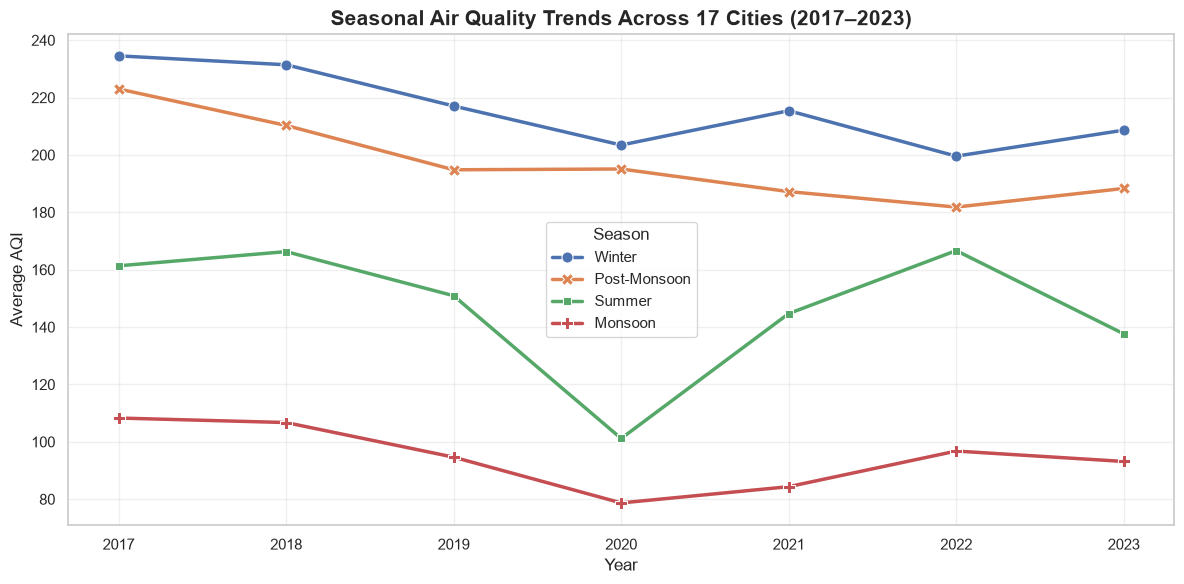

In [76]:
# Prepare data for seasonal trend visualization

season_order = [
    "Winter",
    "Post-Monsoon",
    "Summer",
    "Monsoon"
]

seasonal_pivot = yearly_seasonal_trend.pivot(
    index="Year",
    columns="Season",
    values="Average_AQI"
)

seasonal_pivot = seasonal_pivot[season_order]

# Plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=seasonal_pivot,
    markers=True,
    dashes=False,
    linewidth=2.5,
    markersize=8
)

plt.title(
    "Seasonal Air Quality Trends Across 17 Cities (2017–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Average AQI", fontsize=12)

plt.xticks(range(2017, 2024))
plt.grid(alpha=0.3)
plt.legend(title="Season")
plt.tight_layout()
plt.show()

### Year-wise Seasonal AQI Trends (2017–2023)

The analysis of 17 consistently covered cities reveals that winter remained the most polluted season throughout the study period, while monsoon consistently recorded the lowest average AQI.

Key findings:

- Winter AQI declined from 234.54 in 2017 to 208.64 in 2023, a reduction of approximately 11.02%.
- Post-monsoon AQI declined by approximately 15.56% over the same period.
- Summer AQI showed substantial year-to-year fluctuations, including a notable decline in 2020.
- Monsoon AQI remained comparatively low throughout the observation period.
- All four seasonal averages were lower in 2023 than in 2017.

These results suggest an overall reduction in average AQI between the two comparison years, although year-to-year fluctuations indicate that the pattern was not consistently downward.

*Methodology: Equal-weighted averages of city-level seasonal AQI across 17 cities with complete year-season coverage and at least 500 valid observations per combination.*

## Advanced City-Level Pollution Performance Analysis

### Objective
Evaluate how air quality has changed across the 17 consistently monitored cities between 2017 and 2023.

Key questions:
- Which cities improved the most?
- Which cities experienced worsening air quality?
- Which cities consistently recorded high AQI?
- Are improvements consistent across the selected cities?

In [77]:
# Calculate average AQI for each city in 2017 and 2023

city_start_end = (
    balanced_city_season_year
    .groupby(["State", "City", "Year"])
    .agg(
        Average_AQI=("Average_AQI", "mean")
    )
    .reset_index()
)

city_comparison = city_start_end[
    city_start_end["Year"].isin([2017, 2023])
].pivot(
    index=["State", "City"],
    columns="Year",
    values="Average_AQI"
).reset_index()

city_comparison.columns.name = None

city_comparison = city_comparison.rename(
    columns={
        2017: "AQI_2017",
        2023: "AQI_2023"
    }
)

city_comparison["AQI_Change"] = (
    city_comparison["AQI_2023"] -
    city_comparison["AQI_2017"]
)

city_comparison["Percentage_Change"] = (
    city_comparison["AQI_Change"] /
    city_comparison["AQI_2017"]
) * 100

city_comparison = city_comparison.round(2)

city_comparison.head(17)

,State,City,AQI_2017,AQI_2023,AQI_Change,Percentage_Change
0,Andhra Pradesh,Visakhapatnam,110.31,133.86,23.55,21.35
1,Bihar,Muzaffarpur,185.32,193.36,8.03,4.34
2,Bihar,Patna,219.01,201.79,-17.22,-7.86
3,Delhi,Delhi,234.30,224.23,-10.07,-4.30
4,Haryana,Faridabad,231.78,201.09,-30.69,-13.24
5,Haryana,Gurugram,270.31,200.80,-69.51,-25.71
6,Karnataka,Bengaluru,70.08,76.47,6.39,9.13
7,Maharashtra,Aurangabad,104.55,111.44,6.89,6.59
8,Maharashtra,Mumbai,92.42,129.50,37.08,40.12
9,Punjab,Amritsar,171.42,129.28,-42.14,-24.59


In [78]:
# Rank cities by percentage change in AQI

city_rankings = city_comparison.sort_values(
    by="Percentage_Change",
    ascending=True
).reset_index(drop=True)

print("TOP 5 CITIES WITH AQI IMPROVEMENT")
display(
    city_rankings[
        ["City", "AQI_2017", "AQI_2023", "Percentage_Change"]
    ].head(5)
)

print("TOP 5 CITIES WITH AQI DETERIORATION")
display(
    city_rankings[
        ["City", "AQI_2017", "AQI_2023", "Percentage_Change"]
    ].tail(5).sort_values(
        "Percentage_Change",
        ascending=False
    )
)

TOP 5 CITIES WITH AQI IMPROVEMENT


,City,AQI_2017,AQI_2023,Percentage_Change
0,Ghaziabad,318.64,203.22,-36.22
1,Jodhpur,206.21,137.49,-33.33
2,Mandi Gobindgarh,205.74,147.77,-28.17
3,Gurugram,270.31,200.80,-25.71
4,Amritsar,171.42,129.28,-24.59


TOP 5 CITIES WITH AQI DETERIORATION


,City,AQI_2017,AQI_2023,Percentage_Change
16,Mumbai,92.42,129.50,40.12
15,Visakhapatnam,110.31,133.86,21.35
14,Howrah,107.05,125.88,17.58
13,Bengaluru,70.08,76.47,9.13
12,Aurangabad,104.55,111.44,6.59


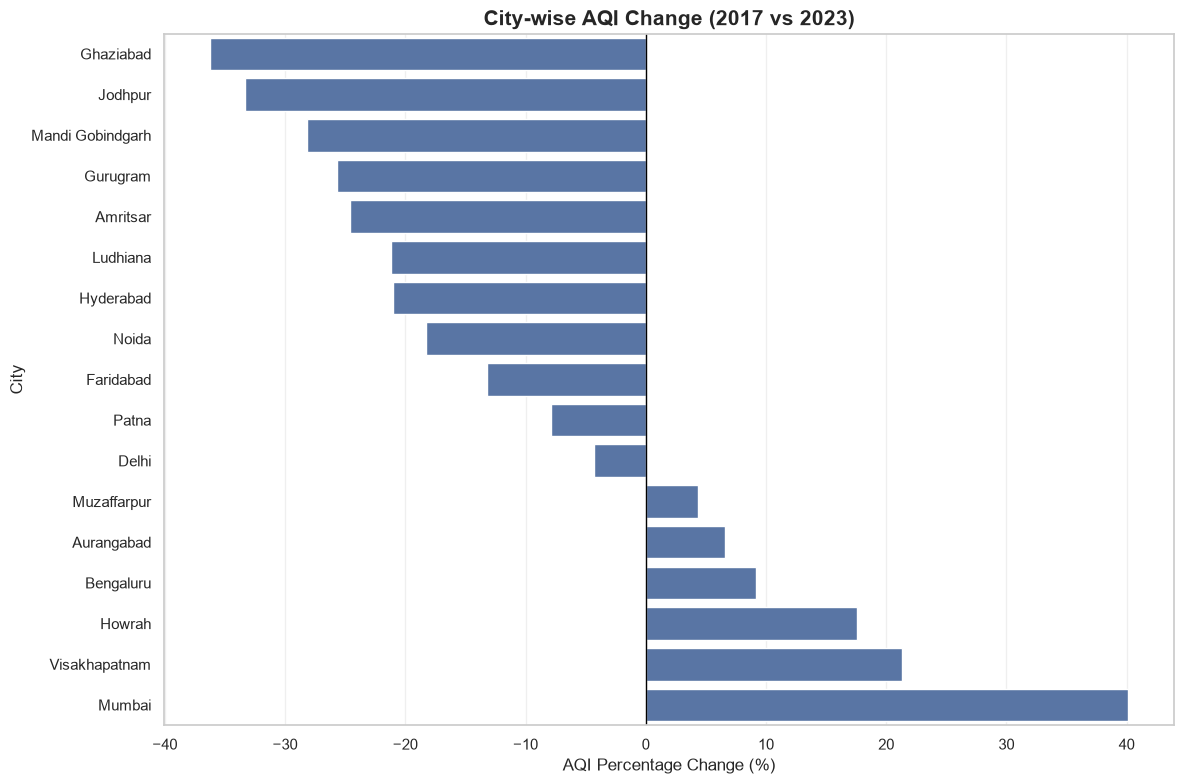

In [79]:
# City-wise AQI percentage change visualization

plt.figure(figsize=(12, 8))

plot_data = city_rankings.sort_values(
    "Percentage_Change",
    ascending=True
)

sns.barplot(
    data=plot_data,
    x="Percentage_Change",
    y="City"
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "City-wise AQI Change (2017 vs 2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("AQI Percentage Change (%)")
plt.ylabel("City")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [80]:
# Calculate long-term AQI performance for each city

city_long_term = (
    balanced_city_season_year
    .groupby(["State", "City"])
    .agg(
        Long_Term_Average_AQI=("Average_AQI", "mean"),
        Median_AQI=("Average_AQI", "median"),
        Minimum_AQI=("Average_AQI", "min"),
        Maximum_AQI=("Average_AQI", "max"),
        Total_Observations=("Valid_Observations", "sum"),
        Year_Season_Combinations=("Average_AQI", "count")
    )
    .reset_index()
)

city_long_term = city_long_term.sort_values(
    "Long_Term_Average_AQI",
    ascending=False
).reset_index(drop=True)

city_long_term = city_long_term.round(2)

city_long_term

,State,City,Long_Term_Average_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,Total_Observations,Year_Season_Combinations
0,Uttar Pradesh,Ghaziabad,252.58,262.14,113.13,412.32,132892,28
1,Uttar Pradesh,Noida,233.11,253.46,106.58,342.46,254860,28
2,Delhi,Delhi,228.07,255.62,99.17,327.53,1777818,28
3,Haryana,Faridabad,218.43,237.55,88.18,333.94,131396,28
4,Haryana,Gurugram,215.22,245.69,94.87,311.67,144826,28
5,Bihar,Patna,201.98,199.52,62.33,352.40,208209,28
6,Bihar,Muzaffarpur,193.38,185.92,60.76,350.10,95016,28
7,Rajasthan,Jodhpur,179.34,180.36,92.15,278.69,79505,28
8,Punjab,Mandi Gobindgarh,152.28,161.56,81.89,282.27,51348,28
9,West Bengal,Howrah,137.93,107.56,48.75,281.66,133889,28


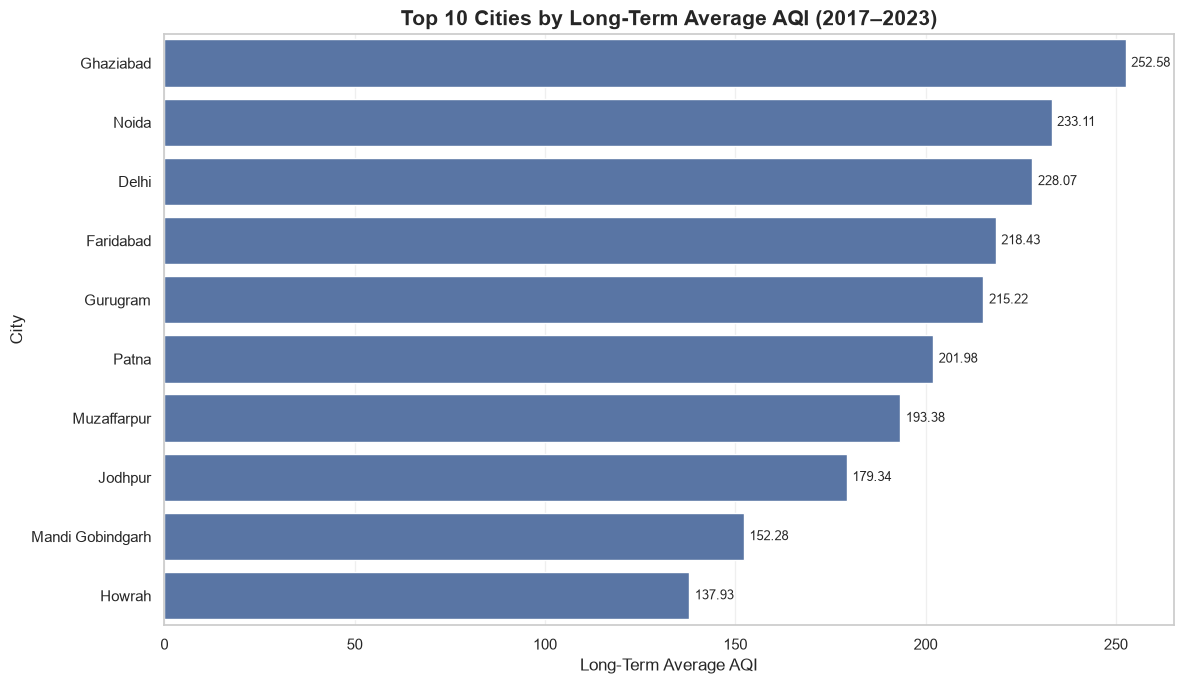

In [81]:
# Top 10 cities with highest long-term average AQI

top_10_long_term = city_long_term.head(10).copy()

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_10_long_term,
    x="Long_Term_Average_AQI",
    y="City"
)

# Add value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=9
    )

plt.title(
    "Top 10 Cities by Long-Term Average AQI (2017–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Long-Term Average AQI")
plt.ylabel("City")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Long-Term City-Level Pollution Performance (2017–2023)

An analysis of 17 cities across seven years and four seasons identified substantial differences in long-term air quality.

**Key findings:**

- Ghaziabad recorded the highest long-term average AQI of 252.58.
- Noida (233.11), Delhi (228.07), Faridabad (218.43) and Gurugram (215.22) completed the top five.
- Patna and Muzaffarpur also recorded high long-term average AQI values.
- Bengaluru recorded the lowest long-term average AQI of 77.01, followed by Hyderabad (96.06).

The results highlight a concentration of high long-term AQI averages among the selected NCR cities, while Bengaluru, Hyderabad and Aurangabad recorded comparatively lower averages.

*Methodology: Equal-weighted average of 28 seasonal-year AQI averages per city, using 17 cities with complete coverage and at least 500 valid observations per year-season combination.*

In [82]:
# Measure AQI variability across 28 seasonal-year combinations

city_variability = (
    balanced_city_season_year
    .groupby(["State", "City"])
    .agg(
        Average_AQI=("Average_AQI", "mean"),
        AQI_Std_Dev=("Average_AQI", "std"),
        Minimum_AQI=("Average_AQI", "min"),
        Maximum_AQI=("Average_AQI", "max")
    )
    .reset_index()
)

city_variability["AQI_Range"] = (
    city_variability["Maximum_AQI"] -
    city_variability["Minimum_AQI"]
)

city_variability = city_variability.round(2)

city_variability = city_variability.sort_values(
    "AQI_Std_Dev",
    ascending=False
).reset_index(drop=True)

city_variability

,State,City,Average_AQI,AQI_Std_Dev,Minimum_AQI,Maximum_AQI,AQI_Range
0,Uttar Pradesh,Ghaziabad,252.58,90.22,113.13,412.32,299.19
1,Bihar,Muzaffarpur,193.38,87.59,60.76,350.10,289.34
2,Bihar,Patna,201.98,81.99,62.33,352.40,290.07
3,Delhi,Delhi,228.07,81.43,99.17,327.53,228.36
4,Haryana,Faridabad,218.43,81.29,88.18,333.94,245.76
5,Uttar Pradesh,Noida,233.11,80.86,106.58,342.46,235.88
6,West Bengal,Howrah,137.93,71.78,48.75,281.66,232.91
7,Haryana,Gurugram,215.22,65.21,94.87,311.67,216.80
8,Punjab,Ludhiana,136.49,50.55,67.77,310.35,242.58
9,Rajasthan,Jodhpur,179.34,47.40,92.15,278.69,186.54


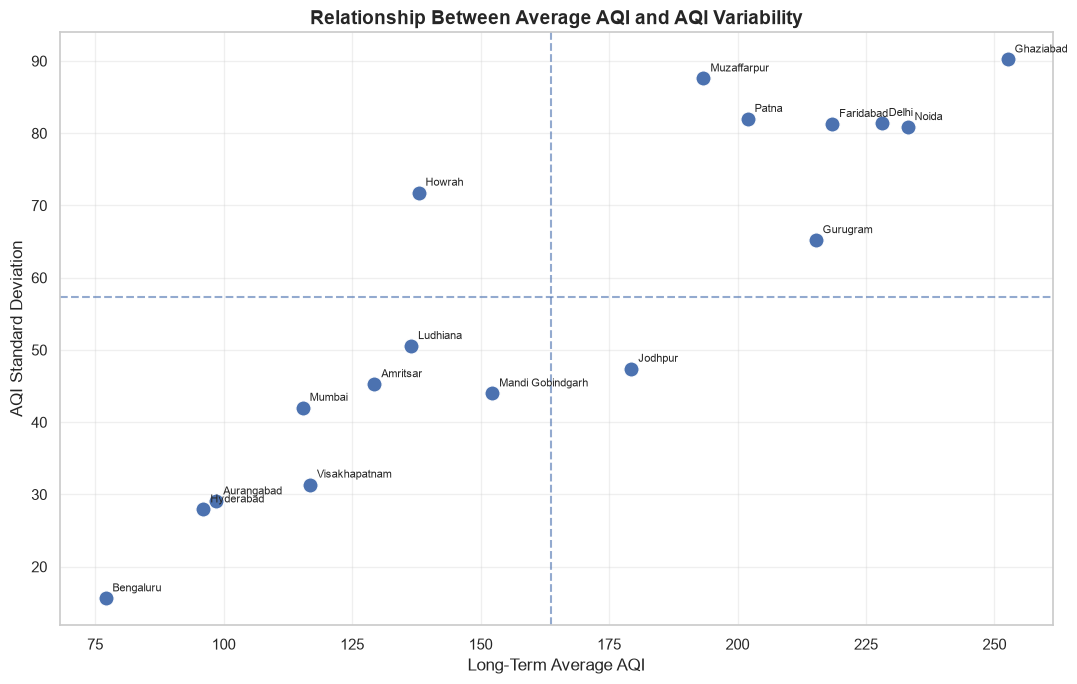

In [83]:
# Relationship between long-term AQI and variability

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=city_variability,
    x="Average_AQI",
    y="AQI_Std_Dev",
    s=120
)

# Add city labels
for _, row in city_variability.iterrows():
    plt.annotate(
        row["City"],
        (row["Average_AQI"], row["AQI_Std_Dev"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Add average reference lines
plt.axvline(
    city_variability["Average_AQI"].mean(),
    linestyle="--",
    alpha=0.6
)

plt.axhline(
    city_variability["AQI_Std_Dev"].mean(),
    linestyle="--",
    alpha=0.6
)

plt.title(
    "Relationship Between Average AQI and AQI Variability",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Long-Term Average AQI")
plt.ylabel("AQI Standard Deviation")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
# Classify cities based on average AQI and variability

avg_aqi_threshold = city_variability["Average_AQI"].mean()
variability_threshold = city_variability["AQI_Std_Dev"].mean()

def classify_city(row):
    if (
        row["Average_AQI"] >= avg_aqi_threshold
        and row["AQI_Std_Dev"] >= variability_threshold
    ):
        return "High AQI - High Variability"

    elif (
        row["Average_AQI"] < avg_aqi_threshold
        and row["AQI_Std_Dev"] >= variability_threshold
    ):
        return "Low AQI - High Variability"

    elif (
        row["Average_AQI"] >= avg_aqi_threshold
        and row["AQI_Std_Dev"] < variability_threshold
    ):
        return "High AQI - Low Variability"

    else:
        return "Low AQI - Low Variability"


city_variability["City_Profile"] = (
    city_variability.apply(classify_city, axis=1)
)

# Display classified cities
city_profiles = city_variability[
    [
        "State",
        "City",
        "Average_AQI",
        "AQI_Std_Dev",
        "City_Profile"
    ]
].sort_values(
    ["City_Profile", "Average_AQI"],
    ascending=[True, False]
)

city_profiles

,State,City,Average_AQI,AQI_Std_Dev,City_Profile
0,Uttar Pradesh,Ghaziabad,252.58,90.22,High AQI - High Variability
5,Uttar Pradesh,Noida,233.11,80.86,High AQI - High Variability
3,Delhi,Delhi,228.07,81.43,High AQI - High Variability
4,Haryana,Faridabad,218.43,81.29,High AQI - High Variability
7,Haryana,Gurugram,215.22,65.21,High AQI - High Variability
2,Bihar,Patna,201.98,81.99,High AQI - High Variability
1,Bihar,Muzaffarpur,193.38,87.59,High AQI - High Variability
9,Rajasthan,Jodhpur,179.34,47.40,High AQI - Low Variability
6,West Bengal,Howrah,137.93,71.78,Low AQI - High Variability
11,Punjab,Mandi Gobindgarh,152.28,43.99,Low AQI - Low Variability


In [85]:
profile_summary = (
    city_profiles["City_Profile"]
    .value_counts()
    .reset_index()
)

profile_summary.columns = [
    "City_Profile",
    "Number_of_Cities"
]

profile_summary

,City_Profile,Number_of_Cities
0,Low AQI - Low Variability,8
1,High AQI - High Variability,7
2,High AQI - Low Variability,1
3,Low AQI - High Variability,1


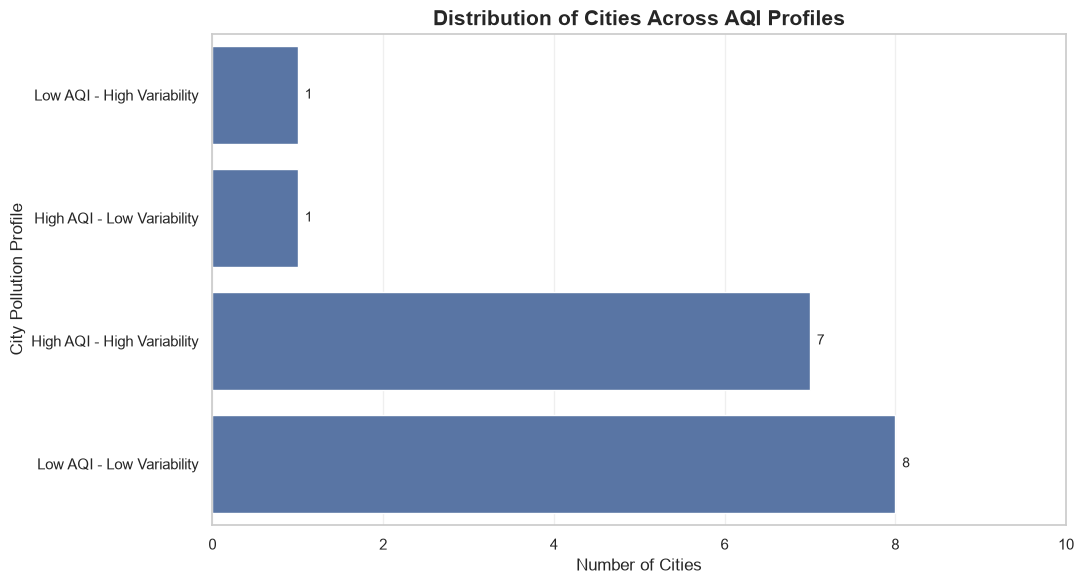

In [86]:
# Visualize number of cities in each pollution profile

profile_plot = profile_summary.sort_values(
    "Number_of_Cities",
    ascending=True
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=profile_plot,
    x="Number_of_Cities",
    y="City_Profile"
)

for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=10)

plt.title(
    "Distribution of Cities Across AQI Profiles",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Cities")
plt.ylabel("City Pollution Profile")
plt.xlim(0, 10)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### City Pollution Profiling Using Average AQI and Variability

The 17 selected cities were classified into four profiles using their long-term average AQI and standard deviation across 28 year-season combinations.

**Key findings:**

- 7 cities (41.18%) fell into the high-average, high-variability category.
- 8 cities (47.06%) fell into the low-average, low-variability category.
- Jodhpur was the only city with high average AQI and relatively low variability.
- Howrah was the only city with low average AQI and high variability.

**Business insight:** City-level air quality monitoring should consider both pollution levels and fluctuations. A city with a high average AQI and substantial variability may require a different monitoring strategy from one with consistently elevated AQI.

*Note: These profiles use relative mean-based thresholds calculated from the selected 17 cities. They are analytical groupings, not official AQI risk categories.*

In [87]:
# Inspect existing AQI categories

print("AQI categories:")
print(df_valid["AQI_Category"].value_counts(dropna=False))

print("\nAQI category percentages:")
print(
    (df_valid["AQI_Category"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMinimum and maximum valid AQI:")
print(df_valid["AQI"].agg(["min", "max"]))

AQI categories:
AQI_Category
Satisfactory    3958356
Moderate        3656970
Good            2278540
Very Poor       1106391
Poor            1023263
Severe           449965
Name: count, dtype: int64

AQI category percentages:
AQI_Category
Satisfactory    31.73
Moderate        29.32
Good            18.27
Very Poor        8.87
Poor             8.20
Severe           3.61
Name: proportion, dtype: float64

Minimum and maximum valid AQI:
min      1.0
max    500.0
Name: AQI, dtype: float64


In [88]:
# Filter valid AQI records to our selected 17 cities

selected_city_data = df_valid.merge(
    eligible_cities_500[["State", "City"]],
    on=["State", "City"],
    how="inner"
)

# Calculate severe pollution statistics city-wise

city_severe_analysis = (
    selected_city_data
    .assign(
        Is_Severe=(
            selected_city_data["AQI_Category"] == "Severe"
        )
    )
    .groupby(["State", "City"])
    .agg(
        Total_Observations=("AQI", "count"),
        Severe_Observations=("Is_Severe", "sum")
    )
    .reset_index()
)

city_severe_analysis["Severe_Percentage"] = (
    city_severe_analysis["Severe_Observations"]
    / city_severe_analysis["Total_Observations"]
    * 100
).round(2)

city_severe_analysis = city_severe_analysis.sort_values(
    "Severe_Observations",
    ascending=False
).reset_index(drop=True)

city_severe_analysis

,State,City,Total_Observations,Severe_Observations,Severe_Percentage
0,Delhi,Delhi,1777818,203399,11.44
1,Uttar Pradesh,Noida,254860,28244,11.08
2,Uttar Pradesh,Ghaziabad,132892,18068,13.60
3,Haryana,Faridabad,131396,12852,9.78
4,Bihar,Patna,208209,11676,5.61
5,Haryana,Gurugram,144826,8019,5.54
6,Maharashtra,Mumbai,752868,7144,0.95
7,Bihar,Muzaffarpur,95016,5560,5.85
8,West Bengal,Howrah,133889,3422,2.56
9,Rajasthan,Jodhpur,79505,1991,2.50


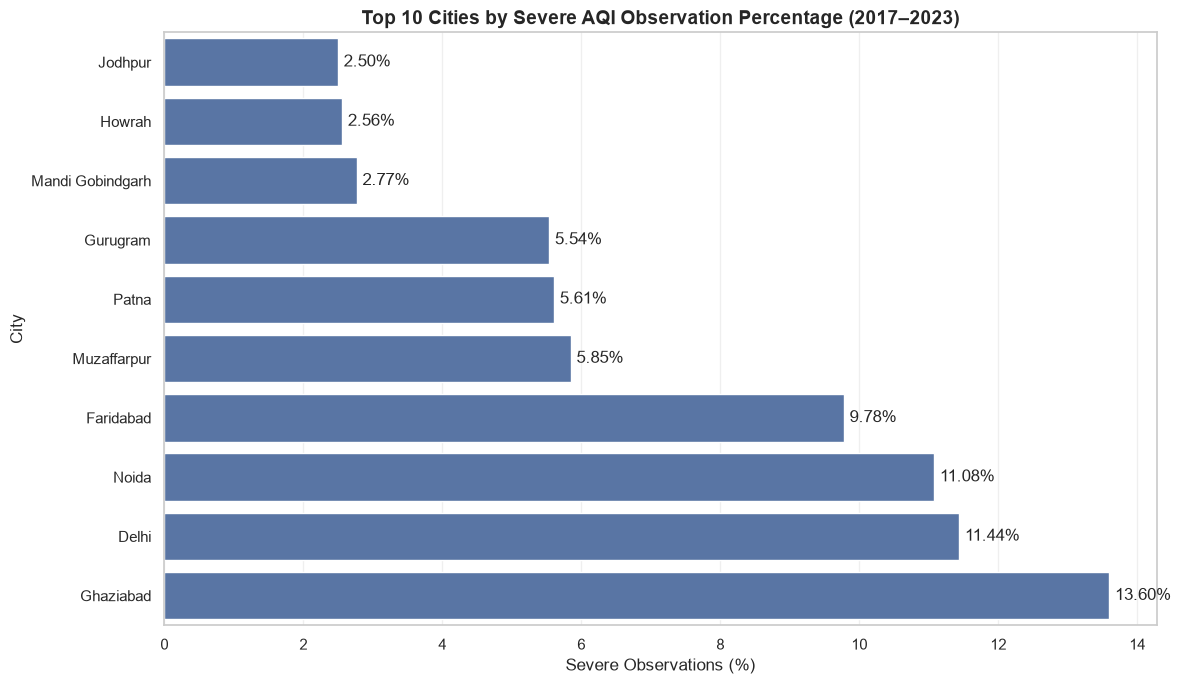

In [89]:
# Top 10 cities by severe AQI percentage

top_10_severe = (
    city_severe_analysis
    .nlargest(10, "Severe_Percentage")
    .sort_values("Severe_Percentage", ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_10_severe,
    x="Severe_Percentage",
    y="City"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4
    )

plt.title(
    "Top 10 Cities by Severe AQI Observation Percentage (2017–2023)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Severe Observations (%)")
plt.ylabel("City")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [90]:
# Monthly severe AQI analysis across all valid observations

monthly_severe = (
    df_valid
    .assign(
        Is_Severe=(df_valid["AQI_Category"] == "Severe")
    )
    .groupby("Month")
    .agg(
        Total_Observations=("AQI", "count"),
        Severe_Observations=("Is_Severe", "sum")
    )
    .reset_index()
)

monthly_severe["Severe_Percentage"] = (
    monthly_severe["Severe_Observations"]
    / monthly_severe["Total_Observations"]
    * 100
).round(2)

monthly_severe["Month_Name"] = pd.to_datetime(
    monthly_severe["Month"],
    format="%m"
).dt.month_name()

monthly_severe

C:\Users\khush\AppData\Local\Temp\ipykernel_35424\454143999.py:22: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  monthly_severe["Month_Name"] = pd.to_datetime(


,Month,Total_Observations,Severe_Observations,Severe_Percentage,Month_Name
0,1,942758,69176,7.34,January
1,2,902427,33100,3.67,February
2,3,1003977,19178,1.91,March
3,4,947722,25151,2.65,April
4,5,982195,20824,2.12,May
5,6,994552,15377,1.55,June
6,7,1055011,5869,0.56,July
7,8,1066639,2932,0.27,August
8,9,1057424,3418,0.32,September
9,10,1140548,37055,3.25,October


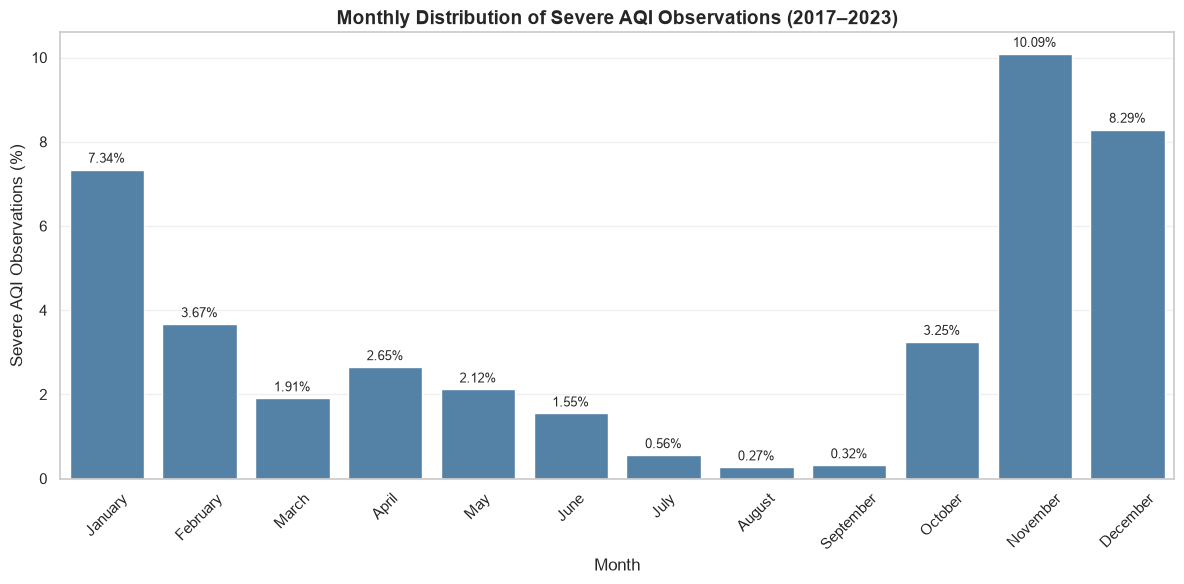

In [91]:
# Monthly distribution of severe AQI observations

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=monthly_severe,
    x="Month_Name",
    y="Severe_Percentage",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

plt.title(
    "Monthly Distribution of Severe AQI Observations (2017–2023)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Month")
plt.ylabel("Severe AQI Observations (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Key Finding — Monthly Severe Pollution Patterns

Severe AQI observations are concentrated in the winter and post-monsoon months. November records the highest severe observation share (10.09%), followed by December (8.29%) and January (7.34%). In contrast, August records the lowest share (0.27%). This highlights a pronounced seasonal pattern in severe air pollution across the monitored cities during 2017–2023.

### Year-wise Trends in Severe AQI Observations

In [92]:
# Year-wise severe AQI analysis

yearly_severe = (
    df_valid
    .assign(
        Is_Severe=df_valid["AQI_Category"].eq("Severe")
    )
    .groupby("Year")
    .agg(
        Total_Observations=("AQI", "count"),
        Severe_Observations=("Is_Severe", "sum")
    )
    .reset_index()
)

yearly_severe["Severe_Percentage"] = (
    yearly_severe["Severe_Observations"]
    / yearly_severe["Total_Observations"] * 100
).round(2)

display(yearly_severe)

,Year,Total_Observations,Severe_Observations,Severe_Percentage
0,2017,240081,20225,8.42
1,2018,877174,59347,6.77
2,2019,1368804,68516,5.01
3,2020,1727659,59483,3.44
4,2021,2162160,79354,3.67
5,2022,2573151,78073,3.03
6,2023,3524456,84967,2.41


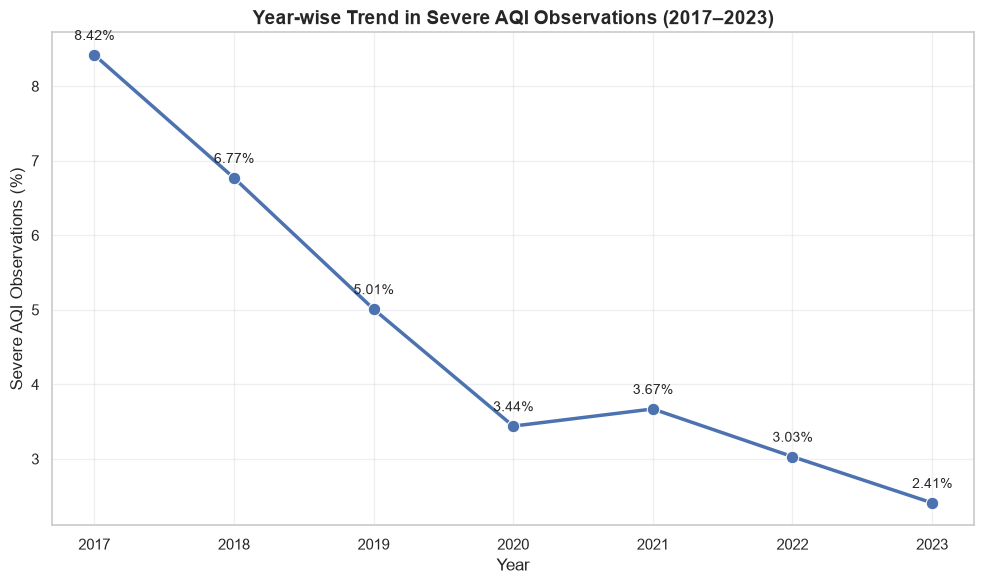

In [93]:
# Year-wise severe AQI trend

plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=yearly_severe,
    x="Year",
    y="Severe_Percentage",
    marker="o",
    linewidth=2.5,
    markersize=9
)

for x, y in zip(
    yearly_severe["Year"],
    yearly_severe["Severe_Percentage"]
):
    plt.text(
        x, y + 0.2,
        f"{y:.2f}%",
        ha="center",
        fontsize=10
    )

plt.title(
    "Year-wise Trend in Severe AQI Observations (2017–2023)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Severe AQI Observations (%)")
plt.xticks(yearly_severe["Year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation: The proportion of severe AQI observations declined from 8.42% in 2017 to 2.41% in 2023, representing an approximate 71.4% relative reduction. A minor increase occurred in 2021. However, the number of valid observations and monitoring coverage increased substantially over the study period. Therefore, these results should be interpreted as changes in the available monitoring dataset rather than a definitive measure of nationwide pollution reduction.

In [94]:
# Season-wise severe AQI analysis

seasonal_severe = (
    df_valid
    .assign(
        Is_Severe=df_valid["AQI_Category"].eq("Severe")
    )
    .groupby("Season")
    .agg(
        Total_Observations=("AQI", "count"),
        Severe_Observations=("Is_Severe", "sum")
    )
    .reset_index()
)

seasonal_severe["Severe_Percentage"] = (
    seasonal_severe["Severe_Observations"]
    / seasonal_severe["Total_Observations"] * 100
).round(2)

display(seasonal_severe)

,Season,Total_Observations,Severe_Observations,Severe_Percentage
0,Monsoon,4173626,27596,0.66
1,Post-Monsoon,2286273,152640,6.68
2,Summer,2933894,65153,2.22
3,Winter,3079692,204576,6.64


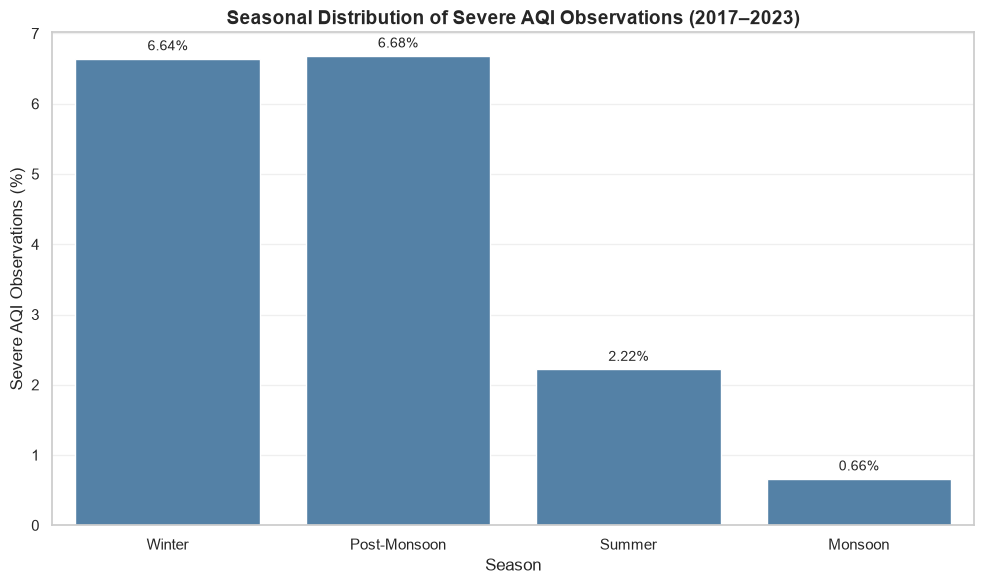

In [95]:
# Seasonal distribution of severe AQI observations

season_order = [
    "Winter",
    "Post-Monsoon",
    "Summer",
    "Monsoon"
]

seasonal_severe_plot = seasonal_severe.copy()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=seasonal_severe_plot,
    x="Season",
    y="Severe_Percentage",
    order=season_order,
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4,
        fontsize=10
    )

plt.title(
    "Seasonal Distribution of Severe AQI Observations (2017–2023)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Season")
plt.ylabel("Severe AQI Observations (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation:
Severe AQI observations are concentrated in the post-monsoon and winter seasons, accounting for 6.68% and 6.64% of their respective valid observations. Monsoon records the lowest severe AQI percentage at 0.66%. These findings demonstrate a strong seasonal variation in severe pollution levels across the monitored cities.

##  Final Exploratory Data Analysis — Key Findings

### 1. Overall AQI Distribution
- Satisfactory: 31.73% of valid observations.
- Moderate: 29.32%.
- Good: 18.27%.
- Very Poor: 8.87%.
- Poor: 8.20%.
- Severe: 3.61%.

### 2. Seasonal Pollution Patterns
- Winter has the highest average AQI (188.96).
- Monsoon has the lowest average AQI (81.25).
- Severe AQI observations are highest in Post-Monsoon (6.68%) and Winter (6.64%).

### 3. Monthly Pollution Patterns
- November has the highest severe AQI observation percentage (10.09%).
- December follows at 8.29%.
- August has the lowest percentage (0.27%).

### 4. Year-wise Severe AQI Trends
- Severe AQI observations declined from 8.42% in 2017 to 2.41% in 2023.
- A small increase occurred in 2021.
- The trend should be interpreted in the context of changing monitoring coverage.

### 5. City-level Pollution Analysis
- Ghaziabad has the highest long-term average AQI among the 17 selected cities (252.58).
- Bengaluru has the lowest (77.01).
- Ghaziabad also has the highest severe AQI observation percentage (13.60%).

### 6. City Pollution Profiles
- 7 cities fall into the High AQI–High Variability profile.
- 8 cities fall into the Low AQI–Low Variability profile.
- Howrah shows Low AQI–High Variability.
- Jodhpur shows High AQI–Low Variability.

### 7. Important Analytical Limitations
- Monitoring station coverage changes across years.
- The 17-city balanced comparison uses a minimum of 500 observations per year-season combination.
- Results represent the available monitoring dataset, not necessarily nationwide population exposure.
- Extreme AQI values above 500 were excluded from standard AQI analysis but retained in the original data for auditing.

In [96]:
# FINAL EDA QUALITY CHECKS

print("=" * 55)
print("FINAL EDA DATA QUALITY VALIDATION")
print("=" * 55)

# 1. Dataset dimensions
print("\n1. Dataset dimensions")
print("Total transformed observations:", len(df))
print("Valid AQI observations:", len(df_valid))

# 2. Missing values
print("\n2. Missing AQI values")
print("Missing AQI values:", df_valid["AQI"].isna().sum())

# 3. AQI range validation
print("\n3. AQI range validation")
print("Minimum AQI:", df_valid["AQI"].min())
print("Maximum AQI:", df_valid["AQI"].max())

# 4. AQI category validation
print("\n4. AQI category validation")
print("Missing categories:", df_valid["AQI_Category"].isna().sum())
print("Unique categories:", df_valid["AQI_Category"].nunique())

# 5. Date and year validation
print("\n5. Time coverage")
print("Start date:", df_valid["Date"].min())
print("End date:", df_valid["Date"].max())
print("Years covered:", sorted(df_valid["Year"].unique()))

# 6. City coverage
print("\n6. Geographic coverage")
print("Number of states:", df_valid["State"].nunique())
print("Number of cities:", df_valid["City"].nunique())

# 7. Balanced comparison validation
print("\n7. Balanced city-season-year dataset")
print("Total records:", len(balanced_city_season_year))
print("Unique cities:", balanced_city_season_year["City"].nunique())
print(
    "Year-season combinations per city:",
    balanced_city_season_year.groupby(["State", "City"]).size().unique()
)

print("\n" + "=" * 55)
print("EDA QUALITY CHECK SUMMARY")
print("=" * 55)

FINAL EDA DATA QUALITY VALIDATION

1. Dataset dimensions
Total transformed observations: 13509072
Valid AQI observations: 12473485

2. Missing AQI values
Missing AQI values: 0

3. AQI range validation
Minimum AQI: 1.0
Maximum AQI: 500.0

4. AQI category validation
Missing categories: 0
Unique categories: 6

5. Time coverage
Start date: 2017-01-01 00:00:00
End date: 2023-12-31 00:00:00
Years covered: [np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]

6. Geographic coverage
Number of states: 29
Number of cities: 248

7. Balanced city-season-year dataset
Total records: 476
Unique cities: 17
Year-season combinations per city: [28]

EDA QUALITY CHECK SUMMARY
